# From Spikes to Decisions: P300 EEG -> Adaptive-LIF SNN -> evidence -> drift-diffusion model (five participants)

Pipeline (unchanged from the single-participant version, now run for every selected participant):

`P300 EEG -> preprocessing -> Adaptive-LIF SNN -> temporal evidence E(t) -> calibrated LLR -> repetition-wise accumulation -> DDM -> speller decision dynamics`

What is new compared with the SBJ01-only notebook

* participants and sessions are discovered automatically from the folder structure, and every result keeps its participant and session identity
* the validation blocks are split in two: one part for early stopping, one part for calibration and every tuned decoding setting, so the held-out session is never used for any choice
* the DDM trial table is built only from genuine held-out evidence (explicit mask and hard checks, no `nan_to_num`)
* the SNN gets three testable additions (heterogeneous adaptive neurons, multiscale temporal input, temporal evidence learning) plus uncertainty-aware sequential decoding, and each one is ablated
* LIF SNN, ANN and LDA are evaluated with exactly the same folds, calibration and decoding
* several seeds, confidence intervals, paired tests, robustness and computational cost

Set `P300_DATA_ROOT` to the folder that contains `SBJ01/`, `SBJ02/`, ... (the notebook also looks for `Dataset/` and `data/` next to itself).
Set `P300_PROFILE=smoke` for a very small test run, `standard` (default) for the real analysis.

In [1]:
import os, math, time, json, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat, whosmat
from scipy.signal import butter, sosfiltfilt
from scipy.stats import norm, wilcoxon
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
import p300_utils as U

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
PROFILE = os.environ.get("P300_PROFILE", "standard")           # "standard" = real analysis, "smoke" = tiny pipeline test
PROFILES = {
    "standard": dict(H1=64, H2=64, BATCH=256, MAX_EPOCHS=30, PATIENCE=6, N_SEEDS_MAIN=1, N_SEEDS_ABL=1, MC_PASSES=8, RUN_ABLATIONS=False),
    "smoke":    dict(H1=24, H2=24, BATCH=128, MAX_EPOCHS=4,  PATIENCE=3, N_SEEDS_MAIN=2, N_SEEDS_ABL=1, MC_PASSES=4, RUN_ABLATIONS=True),
}
CFG = PROFILES[PROFILE]
os.environ["P300_RESULTS"] = "results_b256_check"
RESULTS = Path(os.environ.get("P300_RESULTS", f"results_5p_{PROFILE}")); RESULTS.mkdir(exist_ok=True, parents=True)
CACHE = RESULTS / "cache"; CACHE.mkdir(exist_ok=True)          # every (fold, model, seed) is cached, so a long run can be resumed

# ---- participants
N_PARTICIPANTS = 5
PARTICIPANTS = None       # e.g. ["SBJ01", "SBJ02", "SBJ04", "SBJ05", "SBJ06"] to force a choice; None = first usable ones in sorted order
MIN_SESSIONS = 3          # leave-one-session-out needs at least 2 training sessions plus the held-out one

# ---- signal settings (unchanged)
FS = 250; EPOCH_START_S = -0.2; N_OBJ = 8; BAND = (0.5, 20.0); WIN_S = 0.8; POOL = 4; PRE_BIN = 10
N_CH_EXPECT, N_SAMP_EXPECT = 8, 350

# ---- splits: blocks of the training sessions are divided into train / early-stopping / calibration
ES_FRAC, CAL_FRAC = 0.15, 0.15

# ---- DDM / decision settings (unchanged)
THETA_REF = 3.0
THETAS = [0.5, 1, 1.5, 2, 3, 4, 5, 6]
SEC_PER_REP = None        # seconds per repetition (8 flashes x 300 ms = 2.4 s nominal). Left unset so results stay in repetitions

np.random.seed(SEED)

def find_data_root():
    env = os.environ.get("P300_DATA_ROOT")
    cands = ([Path(env)] if env else []) + [Path(p) for p in ("Dataset", "../Dataset", "data", "../data", "../../Dataset", "dataset")]
    for c in cands:
        if c.is_dir() and any(c.glob("SBJ*")): return c
    raise FileNotFoundError("No folder with SBJ*/ sub-folders found. Set P300_DATA_ROOT. Tried: " + ", ".join(map(str, cands)))

DATA_ROOT = find_data_root()
DATA_KIND = "synthetic" if (DATA_ROOT / "SYNTHETIC_MARKER.txt").exists() else "real"
print(f"Data root: {DATA_ROOT.resolve()}  [{DATA_KIND} data]   profile: {PROFILE}   results -> {RESULTS}")
if DATA_KIND == "synthetic": print("WARNING: synthetic stand-in data. Numbers below only prove the code runs; they are not scientific results.")

Data root: E:\IIT KGP IEEE\Dataset  [real data]   profile: standard   results -> results_b256_check


In [20]:
import numpy as np
r = np.loadtxt(r"E:\IIT KGP IEEE\Dataset\SBJ01\S02\Test\runs_per_block.txt").astype(int).ravel()
print(len(r), r.sum(), r.min(), r.max())

1 7 7 7


## 1. Find usable participants and load every session (Train and Test parts)

A participant is **complete** if every `S*` folder has `Train/` and `Test/` with the data, events and target files, the EEG array has the expected shape (8 channels x 350 samples), every run holds each object once with exactly one target, and the blocks have one attended object. Participants are chosen by this data-integrity rule only (first complete ones in sorted order), never by how well a model performs on them, so the choice cannot bias the comparison. Partially usable participants (at least 3 good sessions) are only used if there are not enough complete ones.

In [2]:
def read_ints(p):
    return np.loadtxt(p).astype(int).ravel()

def pick_eeg(mat, n_epochs):
    arrs = [np.asarray(v) for k, v in mat.items()
            if not k.startswith("__") and np.issubdtype(np.asarray(v).dtype, np.number)]
    A = max(arrs, key=lambda a: a.size)
    assert A.ndim == 3, f"expected a 3-D EEG array, got {A.shape}"
    ax_tr = [i for i, s in enumerate(A.shape) if s == n_epochs][0]
    rest = [i for i in range(3) if i != ax_tr]
    ax_t = rest[0] if A.shape[rest[0]] > A.shape[rest[1]] else rest[1]
    ax_c = [i for i in rest if i != ax_t][0]
    return np.transpose(A, (ax_tr, ax_c, ax_t))            # (epochs, channels, time)

def one_target_per_block(blk, y, ev):
    d = pd.DataFrame({"b": blk, "e": ev, "y": y})
    return bool((d[d.y == 1].groupby("b").e.nunique() == 1).all())

def blocks_from_target_changes(y, ev):
    # a run = 8 consecutive epochs (every object once); a new block starts when the attended object changes
    assert len(y) % N_OBJ == 0, "epoch count is not a multiple of the number of objects"
    r_ev, r_y = ev.reshape(-1, N_OBJ), y.reshape(-1, N_OBJ)
    ok = (np.sort(r_ev, axis=1) == np.arange(ev.min(), ev.min() + N_OBJ)).all(1) & (r_y.sum(1) == 1)
    if not ok.all():
        raise ValueError(f"{int((~ok).sum())} runs are not 8 epochs with each object once and exactly one target: "
                         "check the events/targets files")
    tgt = r_ev[np.arange(len(r_ev)), r_y.argmax(1)]
    run_blk = np.concatenate([[0], np.cumsum(tgt[1:] != tgt[:-1])])
    return np.repeat(run_blk, N_OBJ)

def make_blocks(y, ev, runs, default_per_block):
    """Returns (block id per epoch, where the block structure came from)."""
    n = len(y)
    cand, src = None, None
    if runs is not None and (runs * N_OBJ).sum() == n:
        cand, src = np.repeat(np.arange(len(runs)), runs * N_OBJ), "runs_per_block.txt"
    elif n % default_per_block == 0:
        cand, src = np.arange(n) // default_per_block, "default size"
    if cand is not None and one_target_per_block(cand, y, ev):
        return cand, src
    return blocks_from_target_changes(y, ev), "inferred from target changes"

PARTS = (("Train", "train", 80), ("Test", "test", 48))      # folder, file prefix, default epochs per block

def read_labels(folder, prefix, default_per_block):
    y = read_ints(folder / f"{prefix}Targets.txt"); ev = read_ints(folder / f"{prefix}Events.txt")
    if len(y) != len(ev): raise ValueError("events and targets files have different lengths")
    runs_file = folder / "runs_per_block.txt"
    runs = read_ints(runs_file) if runs_file.exists() else None
    blk, src = make_blocks(y, ev, runs, default_per_block)
    return y, ev, blk, src

def load_part(folder, prefix, default_per_block):
    y, ev, blk, src = read_labels(folder, prefix, default_per_block)
    X = pick_eeg(loadmat(folder / f"{prefix}Data.mat"), len(y))
    return X, y, ev, blk, src

def inspect_session(sd):
    """Cheap integrity check: reads the small text files and only the .mat header (no EEG loaded)."""
    info = dict(session=sd.name, ok=True, issues=[], parts={})
    for part, prefix, per_block in PARTS:
        folder = sd / part
        need = [f"{prefix}Data.mat", f"{prefix}Events.txt", f"{prefix}Targets.txt"]
        miss = [n for n in need if not (folder / n).exists()]
        if miss:
            info["ok"] = False; info["issues"].append(f"{part}: missing {miss}"); continue
        try:
            y, ev, blk, src = read_labels(folder, prefix, per_block)
            shapes = [s for _, s, _ in whosmat(folder / need[0]) if len(s) == 3]
            if not shapes: raise ValueError("no 3-D array in the .mat file")
            s = shapes[0]
            if not (len(y) in s and N_CH_EXPECT in s and N_SAMP_EXPECT in s):
                raise ValueError(f"unexpected EEG shape {s} for {len(y)} epochs")
            info["parts"][part] = dict(n_epochs=len(y), n_targets=int(y.sum()), n_blocks=int(blk.max()) + 1, block_source=src)
        except Exception as e:
            info["ok"] = False; info["issues"].append(f"{part}: {type(e).__name__}: {e}")
    return info

def inspect_subject(sub_dir):
    infos = [inspect_session(p) for p in sorted(sub_dir.glob("S*")) if p.is_dir()]
    good = [i for i in infos if i["ok"]]
    status = "complete" if infos and len(good) == len(infos) and len(good) >= MIN_SESSIONS else \
             "partial" if len(good) >= MIN_SESSIONS else "unusable"
    return dict(subject=sub_dir.name, status=status, sessions=infos, good=[i["session"] for i in good])

inspections = {p.name: inspect_subject(p) for p in sorted(DATA_ROOT.glob("SBJ*")) if p.is_dir()}
rows = []
for sname, ins in inspections.items():
    for s in ins["sessions"]:
        for part, d in s["parts"].items():
            rows.append(dict(subject=sname, session=s["session"], part=part, usable=s["ok"], **d))
        if s["issues"]: rows.append(dict(subject=sname, session=s["session"], part="-", usable=False, issues="; ".join(s["issues"])))
manifest = pd.DataFrame(rows)
manifest.to_csv(RESULTS / "data_manifest.csv", index=False)
print(pd.DataFrame([dict(subject=k, status=v["status"], good_sessions=len(v["good"]), sessions_found=len(v["sessions"])) for k, v in inspections.items()]).to_string(index=False))

if PARTICIPANTS is None:
    order = [k for k, v in inspections.items() if v["status"] == "complete"] + [k for k, v in inspections.items() if v["status"] == "partial"]
    chosen = order[:N_PARTICIPANTS]
else:
    chosen = list(PARTICIPANTS)
    assert all(inspections[c]["status"] != "unusable" for c in chosen), "a requested participant is not usable"
assert len(chosen) == N_PARTICIPANTS, f"only {len(chosen)} usable participants found, need {N_PARTICIPANTS}; see data_manifest.csv"
skipped = {k: [i for s in v["sessions"] for i in s["issues"]] for k, v in inspections.items() if k not in chosen and v["status"] == "unusable"}
for k, v in skipped.items(): print(f"  skipped {k}: {v}")
SUBJECTS = chosen
SESSION_DIRS = {s: [DATA_ROOT / s / n for n in inspections[s]["good"]] for s in SUBJECTS}
print("Selected participants:", {s: [d.name for d in SESSION_DIRS[s]] for s in SUBJECTS})

subject   status  good_sessions  sessions_found
  SBJ01 complete              7               7
  SBJ02 complete              7               7
  SBJ03 complete              7               7
  SBJ04 complete              7               7
  SBJ05 complete              7               7
  SBJ06 complete              7               7
  SBJ07 complete              7               7
  SBJ08 complete              7               7
  SBJ09 complete              7               7
  SBJ10 complete              7               7
  SBJ11 complete              7               7
  SBJ12 complete              7               7
  SBJ13 complete              7               7
  SBJ14 complete              7               7
  SBJ15 complete              7               7
Selected participants: {'SBJ01': ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07'], 'SBJ02': ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07'], 'SBJ03': ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07'], 'SBJ04': ['S01', 'S02', 'S03

## 2. Preprocessing (per session, no cross-trial statistics)

* 0.5-20 Hz zero-phase band-pass (second-order sections, numerically stable)
* baseline = mean of the 200 ms before the flash, subtracted
* keep 0-800 ms, average into 16 ms bins -> **50 SNN time steps x 8 channels**
* **No per-trial z-scoring.** Channel scaling is fitted on training folds only (done inside each fold).
* The raw pre-stimulus segment is kept for a leakage diagnostic.

Every epoch is filtered on its own, so this step uses no information from any other epoch, session or participant.

In [3]:
N_BASE = int(round(-EPOCH_START_S * FS))      # 50 samples
N_WIN = int(round(WIN_S * FS))                # 200 samples
assert N_BASE % PRE_BIN == 0 and N_WIN % POOL == 0
SOS = butter(4, BAND, btype="band", fs=FS, output="sos")

def preprocess_epochs(X):
    Xf = sosfiltfilt(SOS, X.astype(np.float64), axis=-1)
    pre_raw = Xf[:, :, :N_BASE]
    pre = pre_raw.reshape(len(Xf), Xf.shape[1], -1, PRE_BIN).mean(-1).reshape(len(Xf), -1)
    Xc = Xf - pre_raw.mean(-1, keepdims=True)
    win = Xc[:, :, N_BASE:N_BASE + N_WIN]
    win = win.reshape(len(win), win.shape[1], -1, POOL).mean(-1)         # (N, C, 50)
    return win.transpose(0, 2, 1).astype(np.float32), pre.astype(np.float32)

Xb_l, pre_l, y_l, ev_l, blk_l, subj_l, sess_l, part_l = [], [], [], [], [], [], [], []
blk_offset = 0
for pi_, subj in enumerate(SUBJECTS):
    for si, sd in enumerate(SESSION_DIRS[subj]):
        for pi, (part, prefix, per_block) in enumerate(PARTS):
            X, y, ev, blk, src = load_part(sd / part, prefix, per_block)
            xb, pre = preprocess_epochs(X)
            Xb_l.append(xb); pre_l.append(pre); y_l.append(y); ev_l.append(ev)
            blk_l.append(blk + blk_offset); blk_offset += int(blk.max()) + 1
            subj_l.append(np.full(len(y), pi_)); sess_l.append(np.full(len(y), si)); part_l.append(np.full(len(y), pi))
            print(f"  {subj}/{sd.name}/{part:5s}: {len(y):5d} epochs, {int(y.sum()):4d} targets, {int(blk.max()) + 1:3d} blocks "
                  f"(blocks from {src}), raw shape {X.shape}")
            del X

Xb = np.concatenate(Xb_l); PRE = np.concatenate(pre_l)
y_all = np.concatenate(y_l).astype(int); ev_all = np.concatenate(ev_l).astype(int)
blk_all = np.concatenate(blk_l); subj_all = np.concatenate(subj_l); sess_all = np.concatenate(sess_l); part_all = np.concatenate(part_l)
del Xb_l, pre_l

tmp = pd.DataFrame({"b": blk_all, "e": ev_all})
rep_all = (tmp.groupby(["b", "e"]).cumcount() + 1).to_numpy()          # repetition index of that object in that block
N_TOT, T_STEPS, N_CH = Xb.shape

# sanity: exactly one attended object per block, equal repetitions per object
chk = pd.DataFrame({"b": blk_all, "e": ev_all, "y": y_all})
assert (chk[chk.y == 1].groupby("b").e.nunique() == 1).all(), "a block has more than one target object: check targets/events files"
reps_per_obj = chk.groupby(["b", "e"]).size().groupby("b").nunique()
print(f"\nTotal epochs {N_TOT}, targets {int(y_all.sum())} ({y_all.mean():.1%}), blocks {len(np.unique(blk_all))}, model input shape per epoch {Xb.shape[1:]}")
print("Blocks with unequal repetitions across objects:", int((reps_per_obj > 1).sum()))
print("Repetitions per block: min", int(chk.groupby("b").size().min() // N_OBJ), "max", int(chk.groupby("b").size().max() // N_OBJ))
print(pd.DataFrame({"subject": [SUBJECTS[i] for i in subj_all], "session": sess_all}).groupby("subject").agg(
    epochs=("session", "size"), sessions=("session", "nunique")).T.to_string())

  SBJ01/S01/Train:  1600 epochs,  200 targets,  20 blocks (blocks from default size), raw shape (1600, 8, 350)
  SBJ01/S01/Test :  2400 epochs,  300 targets,  50 blocks (blocks from default size), raw shape (2400, 8, 350)
  SBJ01/S02/Train:  1600 epochs,  200 targets,  20 blocks (blocks from default size), raw shape (1600, 8, 350)
  SBJ01/S02/Test :  2800 epochs,  350 targets,  41 blocks (blocks from inferred from target changes), raw shape (2800, 8, 350)
  SBJ01/S03/Train:  1600 epochs,  200 targets,  20 blocks (blocks from default size), raw shape (1600, 8, 350)
  SBJ01/S03/Test :  2800 epochs,  350 targets,  43 blocks (blocks from inferred from target changes), raw shape (2800, 8, 350)
  SBJ01/S04/Train:  1600 epochs,  200 targets,  20 blocks (blocks from default size), raw shape (1600, 8, 350)
  SBJ01/S04/Test :  3600 epochs,  450 targets,  46 blocks (blocks from inferred from target changes), raw shape (3600, 8, 350)
  SBJ01/S05/Train:  1600 epochs,  200 targets,  20 blocks (block

## 3. Leakage check: can the signal BEFORE the flash predict the label?

If this AUC is clearly above 0.5, overlap from the previous flash (short SOA) or an ordering artifact leaks label information, and any "early decision" claim is invalid. It should be about 0.5. The check is now done separately for every participant.

In [4]:
leak_rows = []
for pi_, subj in enumerate(SUBJECTS):
    m = subj_all == pi_
    cv_chk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    pipe = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    a = cross_val_score(pipe, PRE[m], y_all[m], groups=blk_all[m], cv=cv_chk, scoring="roc_auc")
    leak_rows.append(dict(subject=subj, auc_pre=a.mean(), sd=a.std()))
leak = pd.DataFrame(leak_rows); leak.to_csv(RESULTS / "prestimulus_leakage_check.csv", index=False)
print(leak.round(3).to_string(index=False))
print("OK: no meaningful pre-stimulus information." if (leak.auc_pre < 0.55).all() else "  WARNING: pre-stimulus AUC above 0.55 for some participants")

subject  auc_pre    sd
  SBJ01    0.509 0.016
  SBJ02    0.518 0.007
  SBJ03    0.523 0.004
  SBJ04    0.544 0.008
  SBJ05    0.522 0.012
OK: no meaningful pre-stimulus information.


## 4. Folds and the spatiotemporal LDA baseline

Outer protocol: **leave-one-session-out inside each participant**. One fold = one participant with one held-out session; training sessions always come from the same participant, and no data are shared between participants or between folds' test sets.

The blocks of the training sessions are split into three disjoint groups: **train** (about 70%), **early stopping** (15%, SNN/ANN only) and **calibration** (15%: score-to-LLR calibration, uncertainty setting, stopping threshold). All models train on exactly the same `train` epochs. The held-out session is never used for any choice.

The LDA baseline uses 8 channels x 25 time bins (32 ms) = 200 features with automatic shrinkage and exactly the same folds.

In [5]:
folds = {}                                                        # key = (participant index, held-out session index)
for pi_, subj in enumerate(SUBJECTS):
    for k in np.unique(sess_all[subj_all == pi_]):
        te = np.where((subj_all == pi_) & (sess_all == k))[0]
        tr_all = np.where((subj_all == pi_) & (sess_all != k))[0]
        ub = np.unique(blk_all[tr_all]); np.random.default_rng(SEED + 1000 * pi_ + int(k)).shuffle(ub)
        n_es, n_ca = max(1, round(ES_FRAC * len(ub))), max(1, round(CAL_FRAC * len(ub)))
        es_b, ca_b = ub[:n_es], ub[n_es:n_es + n_ca]
        in_es, in_ca = np.isin(blk_all[tr_all], es_b), np.isin(blk_all[tr_all], ca_b)
        f = dict(tr=tr_all[~in_es & ~in_ca], es=tr_all[in_es], ca=tr_all[in_ca], te=te)
        assert not (set(f["tr"]) & set(f["es"])) and not (set(f["tr"]) & set(f["ca"])) and not (set(f["es"]) & set(f["ca"]))
        assert not set(blk_all[f["te"]]) & set(blk_all[tr_all]), "a block appears both in training sessions and in the held-out session"
        folds[(pi_, int(k))] = f

def fold_name(key): return f"{SUBJECTS[key[0]]}/S{key[1] + 1:02d}"
FOLDS_TO_RUN = [(0, k) for k in range(7)]                                               # e.g. [(0, 0)] for a quick trial; None = every fold
run_keys = [k for k in folds if FOLDS_TO_RUN is None or k in FOLDS_TO_RUN]
print(f"{len(folds)} folds ({len(SUBJECTS)} participants). Example {fold_name(next(iter(folds)))}: "
      + ", ".join(f"{n} {len(v)}" for n, v in next(iter(folds.values())).items()))

def lda_features(X):
    n, t, c = X.shape
    return X.reshape(n, t // 2, 2, c).mean(2).reshape(n, -1)

# every model writes into the same containers (NaN = this epoch was never a held-out test epoch)
PERT = U.make_perturbations(N_CH, SEED)                           # test-time corruptions for the robustness study (section 14)
rob_rows = []                                                     # long format: model, fold, perturbation, auc
score, unc, cal_store = {}, {}, {}
def new_stream(name):
    score[name] = np.full(N_TOT, np.nan, dtype=np.float32); unc[name] = np.full(N_TOT, np.nan, dtype=np.float32); cal_store[name] = {}

new_stream("lda")
lda_time = {}
for key in run_keys:
    f = folds[key]; t0 = time.time()
    mu = Xb[f["tr"]].mean(axis=(0, 1), keepdims=True); sd = Xb[f["tr"]].std(axis=(0, 1), keepdims=True) + 1e-8
    clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
    clf.fit(lda_features((Xb[f["tr"]] - mu) / sd), y_all[f["tr"]])
    lda_time[key] = time.time() - t0
    score["lda"][f["te"]] = clf.decision_function(lda_features((Xb[f["te"]] - mu) / sd))
    cal_store["lda"][key] = (clf.decision_function(lda_features((Xb[f["ca"]] - mu) / sd)), None)
    Xte_std = ((Xb[f["te"]] - mu) / sd).astype(np.float32)
    rob_rows.append(dict(model="lda", key=key, perturbation="clean", auc=roc_auc_score(y_all[f["te"]], score["lda"][f["te"]])))
    for pname, spec in PERT.items():
        zp = clf.decision_function(lda_features(U.apply_perturbation(Xte_std, spec, seed=SEED)))
        rob_rows.append(dict(model="lda", key=key, perturbation=pname, auc=roc_auc_score(y_all[f["te"]], zp)))

auc_lda = {k: roc_auc_score(y_all[folds[k]["te"]], score["lda"][folds[k]["te"]]) for k in run_keys}
print("LDA held-out AUC per participant (mean over its sessions):",
      {SUBJECTS[p]: round(float(np.mean([v for (pp, _), v in auc_lda.items() if pp == p])), 3) for p in range(len(SUBJECTS))})
print(f"LDA mean AUC over {len(auc_lda)} held-out sessions = {np.mean(list(auc_lda.values())):.3f} +/- {np.std(list(auc_lda.values()), ddof=1):.3f}")

35 folds (5 participants). Example SBJ01/S01: tr 18576, es 4040, ca 3784, te 4000
LDA held-out AUC per participant (mean over its sessions): {'SBJ01': 0.78, 'SBJ02': nan, 'SBJ03': nan, 'SBJ04': nan, 'SBJ05': nan}
LDA mean AUC over 7 held-out sessions = 0.780 +/- 0.049


c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## 5. Adaptive-LIF SNN, its three proposed components, the plain LIF SNN and the ANN

**Baseline model (the one in the SBJ01 report).** `8 -> 64 AdLIF -> 64 AdLIF -> leaky-integrator readout`. Each neuron has a learnable membrane decay `beta` and a spike-triggered adaptation current with a fixed decay `rho = 0.9`.

**Proposed additions, each switched on or off independently so it can be ablated:**

| switch | what it changes | why it is plausible for P300 |
|---|---|---|
| `adapt="hetero"` | every neuron learns its own adaptation time constant (48-800 ms at initialisation) and a sub-threshold coupling `c` (adaptation also follows the membrane potential, as in the adLIF neuron of Bittar and Garner) | the P300 is a slow, onset-like component; neurons with different adaptation scales act as a bank of high-pass/band-pass temporal filters, and heterogeneous time constants are known to help SNNs on temporal tasks |
| `ms=True` | **multiscale input**: three groups of first-layer neurons read the EEG through causal dilated convolutions (receptive fields about 48, 80 and 144 ms) and start with fast, medium and slow membrane constants | P300 evidence lives on several time scales (N200 to P300 to slow wave); the filter is causal, so the prefix-causal evaluation of E(t) stays valid |
| `tel=True` | **temporal evidence learning**: E(t) is supervised at every time step through a per-step readout, with weights growing toward the end of the epoch, in addition to the final loss | the original model only trained the final logit, so E(t) at early steps was never asked to be informative; now E(t) is trained to be a usable running evidence |

**Uncertainty-aware sequential decoding** is not a network change; it is done at decoding time (section 13) from MC-dropout and seed-ensemble variance.

`lif` is the same network as the baseline with the adaptation removed (the non-adaptive comparison). `ann` is a compact temporal CNN with about the same number of parameters.

In [6]:
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(max(1, os.cpu_count() or 1))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

H1, H2 = CFG["H1"], CFG["H2"]
DROPOUT = 0.2
LR, WD = 3e-3, 1e-3
BATCH, MAX_EPOCHS, PATIENCE = CFG["BATCH"], CFG["MAX_EPOCHS"], CFG["PATIENCE"]
SURR_SLOPE = 4.0         # sharpness of the surrogate gradient
TARGET_RATE, RATE_REG = 0.10, 1e-2
AUG_SHIFT, AUG_NOISE = 2, 0.05     # +-2 bins (32 ms) circular shift, Gaussian noise (in scaled units)
TEL_W = 0.5              # weight of the per-time-step (temporal evidence) loss
DT_MS = POOL * 1000 / FS # 16 ms per SNN step

# All hyperparameters above are fixed in advance (they are the ones of the SBJ01 study plus TEL_W);
# nothing is tuned on held-out sessions. Anything tuned later uses the calibration blocks only.

class SpikeFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return (x > 0).float()
    @staticmethod
    def backward(ctx, g):
        (x,) = ctx.saved_tensors
        return g / (1.0 + SURR_SLOPE * x.abs()) ** 2
spike_fn = SpikeFn.apply

def inv_sigmoid(p): return torch.log(p / (1 - p))
def inv_softplus(v): return torch.log(torch.expm1(torch.as_tensor(v, dtype=torch.float32)))

class CausalMS(nn.Module):
    """Multiscale input current: parallel causal convolutions with dilation 1, 2, 4 (kernel 3)."""
    def __init__(self, n_in, n_out, dilations=(1, 2, 4), k=3):
        super().__init__()
        sizes = [len(a) for a in np.array_split(np.arange(n_out), len(dilations))]
        self.convs = nn.ModuleList([nn.Conv1d(n_in, s, k, dilation=d) for s, d in zip(sizes, dilations)])
        self.pads = [(k - 1) * d for d in dilations]
    def forward(self, x):                                    # (B, T, C) -> (B, T, n_out); no future samples are used
        xt = x.transpose(1, 2)
        return torch.cat([c(F.pad(xt, (p, 0))) for c, p in zip(self.convs, self.pads)], 1).transpose(1, 2)

class SpikingLayer(nn.Module):
    """Leaky integrate-and-fire layer. adapt: 'none' (plain LIF), 'fixed' (original AdLIF, rho = 0.9)
    or 'hetero' (learnable per-neuron rho, adaptation strength b and sub-threshold coupling c)."""
    def __init__(self, inp, n_out, adapt="fixed", beta_ranges=((0.80, 0.97),), b0=0.2, thr=1.0):
        super().__init__()
        self.inp, self.adapt, self.thr = inp, adapt, thr
        parts = [torch.empty(len(a)).uniform_(*r) for a, r in zip(np.array_split(np.arange(n_out), len(beta_ranges)), beta_ranges)]
        self.beta_p = nn.Parameter(inv_sigmoid(torch.cat(parts)))
        if adapt != "none":
            self.b_p = nn.Parameter(torch.full((n_out,), float(inv_softplus(b0))))
        if adapt == "hetero":
            tau = torch.exp(torch.empty(n_out).uniform_(math.log(48.0), math.log(800.0)))   # adaptation time constants (ms)
            self.rho_p = nn.Parameter(inv_sigmoid(torch.exp(-DT_MS / tau)))
            self.c_p = nn.Parameter(torch.full((n_out,), float(inv_softplus(0.05))))
        elif adapt == "fixed":
            self.register_buffer("rho_fixed", torch.tensor(0.9))
    def forward(self, x):                                    # x: (B, T, n_in)
        cur = self.inp(x)                                    # all time steps in one go
        beta = torch.sigmoid(self.beta_p)
        B, T, Hn = cur.shape
        v = cur.new_zeros(B, Hn); w = cur.new_zeros(B, Hn)
        if self.adapt != "none":
            b = F.softplus(self.b_p)
            rho = torch.sigmoid(self.rho_p) if self.adapt == "hetero" else self.rho_fixed
            c = F.softplus(self.c_p) if self.adapt == "hetero" else None
        out = []
        for t in range(T):
            v = beta * v + cur[:, t] - w
            s = spike_fn(v - self.thr)
            v = v - s.detach() * self.thr                    # soft reset
            if self.adapt != "none":
                w = rho * w + b * s                          # spike-frequency adaptation
                if c is not None: w = w + (1 - rho) * c * v  # sub-threshold adaptation (follows the membrane potential)
            out.append(s)
        return torch.stack(out, dim=1)                       # (B, T, Hn)

VARIANTS = {                                                 # name: (adaptation, multiscale input, temporal evidence learning)
    "lif":         dict(adapt="none",   ms=False, tel=False),
    "adlif_base":  dict(adapt="fixed",  ms=False, tel=False),   # model of the SBJ01 report
    "ad_hetero":   dict(adapt="hetero", ms=False, tel=False),
    "ad_ms":       dict(adapt="fixed",  ms=True,  tel=False),
    "ad_tel":      dict(adapt="fixed",  ms=False, tel=True),
    "full":        dict(adapt="hetero", ms=True,  tel=True),    # proposed
    "full_no_het": dict(adapt="fixed",  ms=True,  tel=True),
    "full_no_ms":  dict(adapt="hetero", ms=False, tel=True),
    "full_no_tel": dict(adapt="hetero", ms=True,  tel=False),
    "full_no_ad":  dict(adapt="none",   ms=True,  tel=True),
}
MAIN_NN = ["ann", "lif", "adlif_base", "full"]
ABLATION_ONLY = [v for v in VARIANTS if v not in MAIN_NN]
LABEL = {"lda": "LDA", "ann": "ANN (temporal CNN)", "lif": "LIF SNN", "adlif_base": "Adaptive-LIF (base)", "full": "Adaptive-LIF (proposed)",
         "ad_hetero": "base + heterogeneous adaptation", "ad_ms": "base + multiscale input", "ad_tel": "base + temporal evidence learning",
         "full_no_het": "proposed - heterogeneous adaptation", "full_no_ms": "proposed - multiscale input",
         "full_no_tel": "proposed - temporal evidence learning", "full_no_ad": "proposed - adaptation (LIF)"}

class P300SNN(nn.Module):
    def __init__(self, adapt="fixed", ms=False, tel=False, n_in=8, h1=H1, h2=H2, T=50, drop=DROPOUT):
        super().__init__()
        rng_ms = ((0.60, 0.80), (0.80, 0.92), (0.92, 0.98)) if ms else ((0.80, 0.97),)   # fast / medium / slow membranes
        inp1 = CausalMS(n_in, h1) if ms else nn.Linear(n_in, h1)
        inp2 = nn.Linear(h1, h2)
        with torch.no_grad(): inp2.weight.mul_(2.0)          # larger init for the spike-driven layer so it does not start silent
        self.l1 = SpikingLayer(inp1, h1, adapt, rng_ms)
        self.l2 = SpikingLayer(inp2, h2, adapt, rng_ms)
        self.drop = nn.Dropout(drop)
        self.ro = nn.Linear(h2, 1, bias=False)
        self.ro_beta_p = nn.Parameter(torch.tensor(math.log(0.95 / 0.05)))
        self.tw = nn.Parameter(torch.zeros(T))              # temporal pooling weights (softmax)
        self.tel = tel
        if tel:
            self.a_t = nn.Parameter(torch.ones(T)); self.c_t = nn.Parameter(torch.zeros(T))   # per-step readout of E(t)
        else:
            self.bias = nn.Parameter(torch.zeros(1))
    def forward(self, x):                                   # x: (B, T, C)
        s1 = self.l1(x)
        s2 = self.l2(self.drop(s1))
        cur = self.ro(self.drop(s2)).squeeze(-1)            # (B, T)
        beta = torch.sigmoid(self.ro_beta_p)
        v = cur.new_zeros(cur.shape[0]); E = []
        for t in range(cur.shape[1]):
            v = beta * v + cur[:, t]
            E.append(v)
        E = torch.stack(E, dim=1)                           # evidence trajectory E(t), uses only samples up to t
        w = torch.softmax(self.tw, 0)
        if self.tel:
            zt = E * self.a_t + self.c_t                    # per-step logits (temporal evidence learning)
            logit = (zt * w).sum(1)
        else:
            zt = None
            logit = (E * w).sum(1) + self.bias
        return logit, E, (s1.mean(), s2.mean()), zt

class P300CNN(nn.Module):
    """ANN comparator: two temporal convolutions, pooling, global average, linear output (ELU, dropout 0.2)."""
    def __init__(self, n_in=8, c1=max(4, H1 // 4), c2=max(8, H1 // 2), drop=DROPOUT):
        super().__init__()
        self.c1 = nn.Conv1d(n_in, c1, 7, padding=3); self.c2 = nn.Conv1d(c1, c2, 5, padding=2)
        self.drop = nn.Dropout(drop); self.out = nn.Linear(c2 * (T_STEPS // 4), 1)   # keeps the time axis: P300 latency matters
    def forward(self, x):
        h = F.avg_pool1d(F.elu(self.c1(x.transpose(1, 2))), 2)
        h = F.avg_pool1d(F.elu(self.c2(h)), 2)
        return self.out(self.drop(h.flatten(1))).squeeze(-1), None, None, None

def build_model(name):
    return P300CNN() if name == "ann" else P300SNN(n_in=N_CH, T=T_STEPS, **VARIANTS[name])

def n_params(model): return sum(p.numel() for p in model.parameters())
print({n: n_params(build_model(n)) for n in ["ann", "lif", "adlif_base", "full"]}, "trainable parameters")

Device: cuda NVIDIA GeForce RTX 2050
{'ann': 3889, 'lif': 4980, 'adlif_base': 5108, 'full': 6487} trainable parameters


In [7]:
@torch.no_grad()
def predict(model, X, bs=512, want_E=False):
    model.eval(); zs, Es, r1, r2 = [], [], [], []
    for i in range(0, len(X), bs):
        z, E, rates, _ = model(X[i:i + bs])
        zs.append(z.float().cpu())
        if want_E and E is not None: Es.append(E.float().cpu())
        if rates is not None: r1.append(float(rates[0])); r2.append(float(rates[1]))
    return (torch.cat(zs).numpy(), torch.cat(Es).numpy() if Es else None,
            (np.mean(r1), np.mean(r2)) if r1 else (np.nan, np.nan))

@torch.no_grad()
def predict_mc(model, X, K, bs=512):
    """Epistemic uncertainty: standard deviation of the logit over K stochastic (dropout-on) passes."""
    model.train(); out = []
    for _ in range(K):
        out.append(torch.cat([model(X[i:i + bs])[0].float().cpu() for i in range(0, len(X), bs)]).numpy())
    model.eval()
    return np.std(np.stack(out), axis=0)

def train_one(model_name, Xtr, ytr, Xes, yes, seed, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = build_model(model_name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    n_pos, n_neg = float((ytr == 1).sum()), float((ytr == 0).sum())
    pw = torch.tensor(math.sqrt(n_neg / n_pos), device=DEVICE)
    bce = nn.BCEWithLogitsLoss(pos_weight=pw)
    wt = torch.linspace(0.2, 1.0, Xtr.shape[1], device=DEVICE); wt = wt / wt.sum()   # later steps count more in the TEL loss
    best, best_state, bad, yes_np = -1.0, None, 0, yes.cpu().numpy()
    for ep in range(MAX_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            xb, yb = Xtr[idx], ytr[idx]
            if AUG_SHIFT > 0:
                sh = int(torch.randint(-AUG_SHIFT, AUG_SHIFT + 1, (1,)))
                if sh: xb = torch.roll(xb, sh, dims=1)
            if AUG_NOISE > 0: xb = xb + AUG_NOISE * torch.randn_like(xb)
            logit, _, rates, zt = model(xb)
            loss = bce(logit, yb)
            if rates is not None: loss = loss + RATE_REG * sum((r - TARGET_RATE) ** 2 for r in rates)
            if zt is not None:
                per_step = F.binary_cross_entropy_with_logits(zt, yb[:, None].expand_as(zt), pos_weight=pw, reduction="none")
                loss = loss + TEL_W * (per_step * wt).sum(1).mean()
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step()
        auc = roc_auc_score(yes_np, predict(model, Xes)[0])
        if verbose: print(f"    ep {ep + 1:02d} loss {loss.item():.3f} val AUC {auc:.3f}")
        if auc > best + 1e-4:
            best, bad = auc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, best, ep + 1

## 6. Train and evaluate, leave-one-session-out, all participants

Every (participant, held-out session, model, seed) is trained once and cached to `RESULTS/cache`, so an interrupted run resumes where it stopped. The main models (ANN, LIF, Adaptive-LIF base, proposed) use several seeds; the extra ablation variants use fewer to keep the run affordable (see `PROFILES`). After training, each model gives for the held-out session and for the calibration blocks: the score, an MC-dropout uncertainty (standard deviation over stochastic passes) and, for the SNNs, the evidence trajectory E(t). The main models also score corrupted copies of the held-out epochs (section 14).

In [8]:
NN_MODELS = MAIN_NN + (ABLATION_ONLY if CFG["RUN_ABLATIONS"] else [])
E_MODELS = ["lif", "adlif_base", "full"]                         # models whose E(t) is kept for the time-resolved analysis
def seeds_of(m): return list(range(CFG["N_SEEDS_MAIN"] if m in MAIN_NN else CFG["N_SEEDS_ABL"]))
def cache_path(key, m, s): return CACHE / f"{SUBJECTS[key[0]]}_S{key[1] + 1:02d}__{m}__s{s}.npz"

def fold_data(key):
    f = folds[key]
    mu = Xb[f["tr"]].mean(axis=(0, 1), keepdims=True); sd = Xb[f["tr"]].std(axis=(0, 1), keepdims=True) + 1e-8   # training statistics only
    return {n: ((Xb[f[n]] - mu) / sd).astype(np.float32) for n in ("tr", "es", "ca", "te")}

def run_job(m, key, seed, D):
    f = folds[key]
    tt = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    Xtr, Xes, Xca, Xte = tt(D["tr"]), tt(D["es"]), tt(D["ca"]), tt(D["te"])
    ytr, yes = tt(y_all[f["tr"]]), tt(y_all[f["es"]])
    t0 = time.time()
    model, best, n_ep = train_one(m, Xtr, ytr, Xes, yes, seed=SEED + 10000 * key[0] + 100 * key[1] + seed)
    train_s = time.time() - t0
    t1 = time.time(); z_te, E_te, rates = predict(model, Xte, want_E=m in E_MODELS); infer_s = time.time() - t1
    z_ca = predict(model, Xca)[0]
    u_te, u_ca = predict_mc(model, Xte, CFG["MC_PASSES"]), predict_mc(model, Xca, CFG["MC_PASSES"])
    rob = {}
    if seed == 0 and m in MAIN_NN:                                  # robustness: same trained model, corrupted held-out input
        rob["clean"] = roc_auc_score(y_all[f["te"]], z_te)
        for pname, spec in PERT.items():
            rob[pname] = roc_auc_score(y_all[f["te"]], predict(model, tt(U.apply_perturbation(D["te"], spec, seed=SEED)))[0])
    out = dict(z_te=z_te, u_te=u_te, z_ca=z_ca, u_ca=u_ca, rates=np.array(rates), best=best, epochs=n_ep, train_s=train_s,
               infer_ms=1000 * infer_s / len(z_te), rob_names=np.array(list(rob)), rob_vals=np.array(list(rob.values()), float))
    if E_te is not None: out["E_te"] = E_te
    np.savez_compressed(cache_path(key, m, seed), **out)
    del model, Xtr, Xes, Xca, Xte
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return train_s

jobs = [(key, m, s) for key in run_keys for m in NN_MODELS for s in seeds_of(m)]
todo = [j for j in jobs if not cache_path(*j).exists()]
print(f"{len(jobs)} training jobs, {len(jobs) - len(todo)} already cached, {len(todo)} to run")
times, t_start, cur_key, D = [], time.time(), None, None
for i, (key, m, s) in enumerate(todo):
    if key != cur_key: D, cur_key = fold_data(key), key
    ts = run_job(m, key, s, D); times.append(ts)
    eta = np.mean(times) * (len(todo) - i - 1) / 3600
    print(f"[{i + 1}/{len(todo)}] {fold_name(key)} {m} seed {s}: {ts:.0f}s  (mean {np.mean(times):.0f}s/job, about {eta:.1f} h left)")

# ---- assemble streams from the cache: `m` = ensemble of all its seeds, `m@s0` = seed 0 only (same seed for every variant)
seed_rows, E_traj = [], {}
def load(key, m, s): return np.load(cache_path(key, m, s))
for m in NN_MODELS:
    names = {m + "@s0": [0]}
    if m in MAIN_NN: names[m] = seeds_of(m)
    for name, ss in names.items():
        new_stream(name)
        if m in E_MODELS and name == m: E_traj[name] = np.full((N_TOT, T_STEPS), np.nan, dtype=np.float32)
        for key in run_keys:
            f = folds[key]; R = [load(key, m, s) for s in ss]
            Zt, Zc = np.stack([r["z_te"] for r in R]), np.stack([r["z_ca"] for r in R])
            ut2 = np.mean([r["u_te"] ** 2 for r in R], 0) + Zt.var(0); uc2 = np.mean([r["u_ca"] ** 2 for r in R], 0) + Zc.var(0)   # total variance
            score[name][f["te"]] = Zt.mean(0); unc[name][f["te"]] = np.sqrt(ut2)
            cal_store[name][key] = (Zc.mean(0), np.sqrt(uc2))
            if name in E_traj: E_traj[name][f["te"]] = np.mean([r["E_te"] for r in R], 0)
    for key in run_keys:
        for s in seeds_of(m):
            r = load(key, m, s)
            seed_rows.append(dict(subject=SUBJECTS[key[0]], session=key[1] + 1, model=m, seed=s, auc=roc_auc_score(y_all[folds[key]["te"]], r["z_te"]),
                                  best_val_auc=float(r["best"]), epochs=int(r["epochs"]), train_s=float(r["train_s"]), infer_ms=float(r["infer_ms"]),
                                  rate1=float(r["rates"][0]), rate2=float(r["rates"][1])))
            if s == 0 and m in MAIN_NN:
                rob_rows += [dict(model=m, key=key, perturbation=n, auc=float(v)) for n, v in zip(r["rob_names"], r["rob_vals"])]
seed_df = pd.DataFrame(seed_rows); seed_df.to_csv(RESULTS / "per_seed_results.csv", index=False)
print(seed_df.groupby("model").agg(auc=("auc", "mean"), epochs=("epochs", "mean"), train_s=("train_s", "mean")).round(3).to_string())

28 training jobs, 0 already cached, 28 to run
[1/28] SBJ01/S01 ann seed 0: 11s  (mean 11s/job, about 0.1 h left)
[2/28] SBJ01/S01 lif seed 0: 37s  (mean 24s/job, about 0.2 h left)
[3/28] SBJ01/S01 adlif_base seed 0: 209s  (mean 86s/job, about 0.6 h left)
[4/28] SBJ01/S01 full seed 0: 266s  (mean 131s/job, about 0.9 h left)
[5/28] SBJ01/S02 ann seed 0: 8s  (mean 106s/job, about 0.7 h left)
[6/28] SBJ01/S02 lif seed 0: 109s  (mean 107s/job, about 0.7 h left)
[7/28] SBJ01/S02 adlif_base seed 0: 197s  (mean 120s/job, about 0.7 h left)
[8/28] SBJ01/S02 full seed 0: 235s  (mean 134s/job, about 0.7 h left)
[9/28] SBJ01/S03 ann seed 0: 8s  (mean 120s/job, about 0.6 h left)
[10/28] SBJ01/S03 lif seed 0: 85s  (mean 116s/job, about 0.6 h left)
[11/28] SBJ01/S03 adlif_base seed 0: 185s  (mean 123s/job, about 0.6 h left)
[12/28] SBJ01/S03 full seed 0: 271s  (mean 135s/job, about 0.6 h left)
[13/28] SBJ01/S04 ann seed 0: 6s  (mean 125s/job, about 0.5 h left)
[14/28] SBJ01/S04 lif seed 0: 33s  (mean 

## 7. Single-trial classification: LDA, ANN, LIF, Adaptive-LIF (held-out sessions)

AUC of the seed-ensemble score on every held-out session, reported per participant (mean over its sessions with a 95% bootstrap CI) and pooled (hierarchical bootstrap: participants, then sessions). `auc_seedmean` is the mean of the individual seeds, i.e. without the benefit of ensembling.

e:\IIT KGP IEEE\Analysis\p300_utils.py:22: RuntimeWarning: Mean of empty slice.
  m = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
e:\IIT KGP IEEE\Analysis\p300_utils.py:23: RuntimeWarning: Mean of empty slice.
  return float(x.mean()), *np.percentile(m, [2.5, 97.5])
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Held-out ROC-AUC, mean [95% CI]
                          LDA    ANN (temporal CNN)               LIF SNN   Adaptive-LIF (base) Adaptive-LIF (proposed)
SBJ01   0.780 [0.744, 0.810]  0.784 [0.751, 0.814]  0.519 [0.510, 0.527]  0.647 [0.632, 0.662]    0.696 [0.673, 0.719]
SBJ02         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ03         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ04         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ05         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
Pooled  0.780 [0.744, 0.810]  0.784 [0.751, 0.814]  0.519 [0.510, 0.527]  0.647 [0.632, 0.662]    0.696 [0.673, 0.719]

Proposed Adaptive-LIF minus each reference (paired over held-out sessions; Holm over the 4 comparisons):
model        ref  n_sessions

e:\IIT KGP IEEE\Analysis\p300_utils.py:22: RuntimeWarning: Mean of empty slice.
  m = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
e:\IIT KGP IEEE\Analysis\p300_utils.py:23: RuntimeWarning: Mean of empty slice.
  return float(x.mean()), *np.percentile(m, [2.5, 97.5])
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


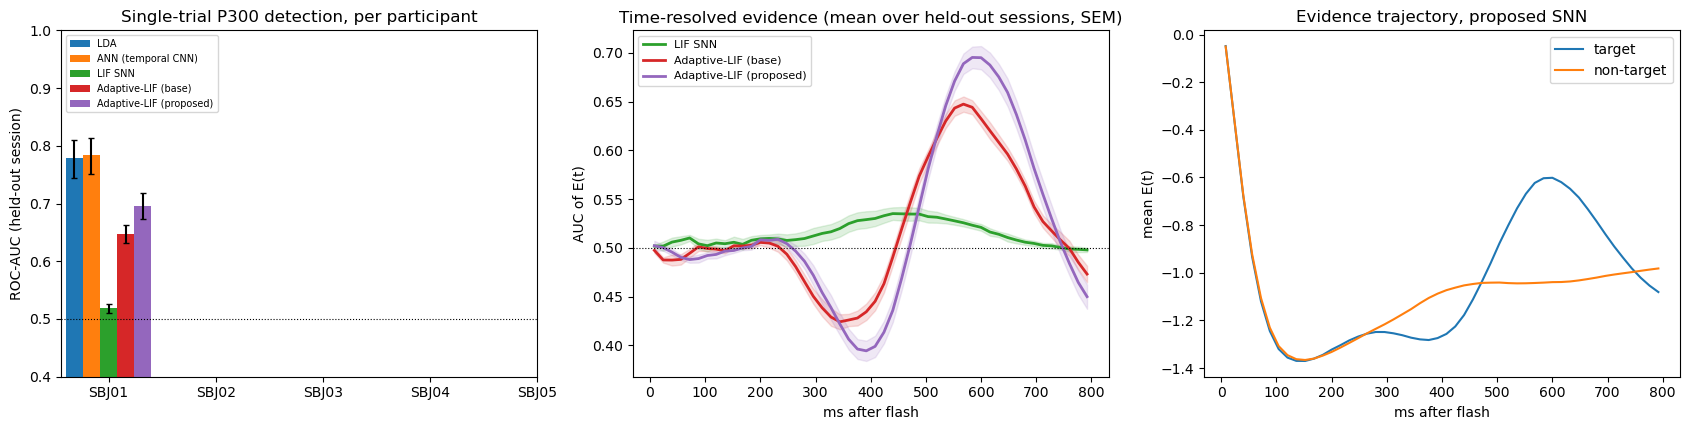

In [9]:
MAIN = ["lda", "ann", "lif", "adlif_base", "full"]
def session_auc(stream):
    return {k: roc_auc_score(y_all[folds[k]["te"]], score[stream][folds[k]["te"]]) for k in run_keys}

rows = []
for m in MAIN:
    a = session_auc(m)
    for k in run_keys:
        sm = seed_df[(seed_df.model == m) & (seed_df.subject == SUBJECTS[k[0]]) & (seed_df.session == k[1] + 1)].auc.mean() if m != "lda" else a[k]
        rows.append(dict(subject=SUBJECTS[k[0]], session=k[1] + 1, model=m, auc=a[k], auc_seedmean=sm,
                         n_test=len(folds[k]["te"]), n_targets=int(y_all[folds[k]["te"]].sum())))
res_auc = pd.DataFrame(rows); res_auc.to_csv(RESULTS / "single_trial_auc_per_session.csv", index=False)

def summarise(df, value, models, labels=LABEL):
    out = {}
    for subj in SUBJECTS:
        out[subj] = {labels[m]: "%.3f [%.3f, %.3f]" % U.session_bootstrap(df[(df.model == m) & (df.subject == subj)][value]) for m in models}
    out["Pooled"] = {labels[m]: "%.3f [%.3f, %.3f]" % U.two_level_bootstrap(df[df.model == m], value) for m in models}
    return pd.DataFrame(out).T
tab7 = summarise(res_auc, "auc", MAIN); tab7.to_csv(RESULTS / "table_auc_per_participant.csv")
print("Held-out ROC-AUC, mean [95% CI]\n", tab7.to_string())

ref_models = ["lda", "ann", "lif", "adlif_base"]
cmp7 = U.family_vs(res_auc, "auc", "full", ref_models); cmp7.to_csv(RESULTS / "stats_auc_proposed_vs_others.csv", index=False)
print("\nProposed Adaptive-LIF minus each reference (paired over held-out sessions; Holm over the 4 comparisons):")
print(cmp7.round(4).to_string(index=False))
chi, pf = U.friedman(res_auc, "auc", MAIN); print(f"Friedman test across the five methods: chi2 = {chi:.2f}, p = {pf:.2g}")

# time-resolved AUC of the evidence trajectory E(t) over 0-800 ms (SNN models; prefix-causal by construction)
t_ms = (np.arange(T_STEPS) + 0.5) * POOL * 1000 / FS
def hm_se(auc, n1, n0):
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n1 - 1) * (q1 - auc ** 2) + (n0 - 1) * (q2 - auc ** 2)) / (n1 * n0))

temporal, lat_rows = {}, []
for m in E_MODELS:
    for k in run_keys:
        te = folds[k]["te"]; yt = y_all[te]; n1, n0 = int(yt.sum()), int((yt == 0).sum())
        a = np.array([roc_auc_score(yt, E_traj[m][te, t]) for t in range(T_STEPS)])
        temporal[(m, k)] = a
        sig = a > 0.5 + 2 * hm_se(a, n1, n0)
        run3 = [i for i in range(T_STEPS - 2) if sig[i] and sig[i + 1] and sig[i + 2]]
        top = a.max(); t90 = t_ms[int(np.argmax(a >= 0.5 + 0.9 * (top - 0.5)))]
        lat_rows.append(dict(model=m, subject=SUBJECTS[k[0]], session=k[1] + 1, onset_ms=t_ms[run3[0]] if run3 else np.nan,
                             peak_auc=top, peak_ms=t_ms[int(np.argmax(a))], t90_ms=t90, final_auc=a[-1]))
lat = pd.DataFrame(lat_rows); lat.to_csv(RESULTS / "within_epoch_latency.csv", index=False)
print("\nWithin-epoch evidence (SNN E(t)), mean over held-out sessions:")
print(lat.groupby("model")[["onset_ms", "peak_auc", "peak_ms", "t90_ms"]].agg(["mean", "std"]).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
w = 0.16; xs = np.arange(len(SUBJECTS))
for j, m in enumerate(MAIN):
    mu = [res_auc[(res_auc.model == m) & (res_auc.subject == s)].auc.mean() for s in SUBJECTS]
    ci = np.array([U.session_bootstrap(res_auc[(res_auc.model == m) & (res_auc.subject == s)].auc)[1:] for s in SUBJECTS])
    ax[0].bar(xs + (j - 2) * w, mu, w, yerr=[np.array(mu) - ci[:, 0], ci[:, 1] - np.array(mu)], label=LABEL[m], capsize=2)
ax[0].axhline(0.5, color="k", lw=0.8, ls=":"); ax[0].set_xticks(xs); ax[0].set_xticklabels(SUBJECTS); ax[0].set_ylim(0.4, 1.0)
ax[0].set_ylabel("ROC-AUC (held-out session)"); ax[0].set_title("Single-trial P300 detection, per participant"); ax[0].legend(fontsize=7)
for j, m in enumerate(E_MODELS):
    A = np.vstack([temporal[(m, k)] for k in run_keys]); mu = A.mean(0)
    ax[1].plot(t_ms, mu, color=f"C{j + 2}", lw=2, label=LABEL[m]); ax[1].fill_between(t_ms, mu - A.std(0, ddof=1) / np.sqrt(len(A)), mu + A.std(0, ddof=1) / np.sqrt(len(A)), color=f"C{j + 2}", alpha=0.15)
ax[1].axhline(0.5, color="k", lw=0.8, ls=":"); ax[1].set_xlabel("ms after flash"); ax[1].set_ylabel("AUC of E(t)"); ax[1].set_title("Time-resolved evidence (mean over held-out sessions, SEM)"); ax[1].legend(fontsize=8)
te_all = np.concatenate([folds[k]["te"] for k in run_keys])
for c, lab in ((1, "target"), (0, "non-target")):
    ax[2].plot(t_ms, np.nanmean(E_traj["full"][te_all][y_all[te_all] == c], 0), label=lab)
ax[2].set_xlabel("ms after flash"); ax[2].set_ylabel("mean E(t)"); ax[2].set_title("Evidence trajectory, proposed SNN"); ax[2].legend()
plt.tight_layout(); plt.savefig(RESULTS / "fig1_single_trial_and_temporal.png", dpi=200); plt.show()

## 8. From scores to evidence: calibrated log-likelihood ratios (held-out evidence only)

Each flash score is mapped to a log-likelihood ratio with an equal-variance Gaussian model fitted on the **calibration blocks of the same fold** (never on the held-out session):

`LLR(z) = (mu1 - mu0) / sigma^2 * (z - (mu1 + mu0) / 2)`, with sensitivity `d' = (mu1 - mu0) / sigma`.

Under this model the LLR increments have mean `+-d'^2/2` and standard deviation `d'`, which is exactly a drift-diffusion process once divided by `d'`.

**Uncertainty-aware evidence** (`*_ua`): the epistemic variance `u^2` of a flash score (MC-dropout plus seed disagreement) widens the class-conditional distributions, so an uncertain flash contributes less: `LLR_ua = LLR / (1 + kappa * u^2 / mean(u^2))`. `kappa` is chosen from a small grid on the calibration blocks only (area under the accuracy-vs-repetitions curve); it stays 0 unless it improves that curve by at least 0.5 points.

**Test-set construction (corrected).** The DDM and speller trial tables are built from an explicit `heldout` mask: only epochs of a session that was held out in its own fold, scored by a model that never saw that session. There is no `nan_to_num`; a NaN in the evidence raises an error, ragged repetition counts are tracked by a `valid` mask, and every block must come from a single held-out session.

In [10]:
def fit_llr(zv, yv):
    m1, m0 = zv[yv == 1].mean(), zv[yv == 0].mean()
    var = (((zv[yv == 1] - m1) ** 2).sum() + ((zv[yv == 0] - m0) ** 2).sum()) / (len(zv) - 2)
    return (m1 - m0) / var, (m1 + m0) / 2, (m1 - m0) / np.sqrt(var)

heldout = np.zeros(N_TOT, bool)
for k in run_keys: heldout[folds[k]["te"]] = True               # the only epochs that may enter any decision/DDM analysis
HO_IDX = np.where(heldout)[0]
print(f"Held-out epochs: {heldout.sum()} of {N_TOT} ({len(run_keys)} folds)")

def build_trials(idx, llr_vals):
    """One trial = one (block, object); increments are the per-repetition LLRs. `valid` marks real repetitions (the rest is padding)."""
    d = pd.DataFrame({"subj": subj_all[idx], "sess": sess_all[idx], "blk": blk_all[idx], "obj": ev_all[idx],
                      "rep": rep_all[idx], "y": y_all[idx], "llr": np.asarray(llr_vals, float)})
    if not np.isfinite(d.llr).all():
        raise ValueError(f"{int((~np.isfinite(d.llr)).sum())} epochs without held-out evidence reached the trial table")
    if (d.groupby("blk").sess.nunique() > 1).any() or (d.groupby("blk").subj.nunique() > 1).any():
        raise ValueError("a block mixes several sessions or participants")
    d = d.sort_values(["blk", "obj", "rep"])
    g = d.groupby(["blk", "obj"], sort=True)
    tid = g.ngroup().to_numpy(); pos = g.cumcount().to_numpy()
    R = np.bincount(tid); inc = np.full((len(R), R.max()), np.nan); inc[tid, pos] = d["llr"].to_numpy()
    first = np.r_[0, np.cumsum(R)[:-1]]
    return dict(inc=inc, valid=~np.isnan(inc), R=R, y=d["y"].to_numpy()[first], subj=d["subj"].to_numpy()[first],
                sess=d["sess"].to_numpy()[first], blk=d["blk"].to_numpy()[first], obj=d["obj"].to_numpy()[first])

def blocks_of(tr):
    """Group the trial table into speller blocks: increments (8 objects x repetitions), cumulative evidence and the target object."""
    order = np.argsort(tr["blk"], kind="stable"); cuts = np.flatnonzero(np.diff(tr["blk"][order])) + 1
    out = []
    for idx in np.split(order, cuts):
        assert len(idx) == N_OBJ, "a block does not contain all objects"
        Rb = int(tr["R"][idx].min()); inc = tr["inc"][idx][:, :Rb]; assert np.isfinite(inc).all()
        out.append(dict(subj=int(tr["subj"][idx[0]]), sess=int(tr["sess"][idx[0]]), blk=int(tr["blk"][idx[0]]),
                        tgt=int(np.argmax(tr["y"][idx])), Rb=Rb, inc=inc, cum=np.cumsum(inc, axis=1)))
    return out

def aurc(blocks, r_cap=10):
    """Area under the accuracy-vs-repetitions curve (mean correctness over the first r_cap repetitions common to all blocks)."""
    r = min(r_cap, min(b["Rb"] for b in blocks))
    return float(np.mean([(b["cum"][:, :r].argmax(0) == b["tgt"]).mean() for b in blocks]))

KAPPAS = [0, 0.25, 0.5, 1, 2, 4]; KAPPA_MIN_GAIN = 0.005
EVID = {}
def get_evidence(name):
    """name = score stream, or '<stream>_ua' for the uncertainty-aware version. Calibration uses the fold's calibration blocks only."""
    if name in EVID: return EVID[name]
    use_u = name.endswith("_ua"); base = name[:-3] if use_u else name
    llr = np.full(N_TOT, np.nan); llr_cal, dp, kap = {}, {}, {}
    for key in run_keys:
        f = folds[key]; z_ca, u_ca = cal_store[base][key]; y_ca = y_all[f["ca"]]
        gain, mid, d = fit_llr(z_ca, y_ca)
        shrink = lambda u, kappa: 1.0 / (1.0 + kappa * u ** 2 / np.mean(u_ca ** 2)) if (use_u and kappa > 0) else 1.0
        best_k, best_a, base_a = 0, -1, None
        for kappa in (KAPPAS if use_u else [0]):
            a = aurc(blocks_of(build_trials(f["ca"], gain * (z_ca - mid) * shrink(u_ca, kappa))))
            if kappa == 0: base_a = a
            if a > best_a + 1e-12 and (kappa == 0 or a >= base_a + KAPPA_MIN_GAIN): best_k, best_a = kappa, a
        llr_cal[key] = gain * (z_ca - mid) * shrink(u_ca, best_k)
        te = f["te"]; llr[te] = gain * (score[base][te] - mid) * (shrink(unc[base][te], best_k) if use_u else 1.0)
        dp[key] = float(np.sqrt((llr_cal[key][y_ca == 1].var() * (y_ca == 1).sum() + llr_cal[key][y_ca == 0].var() * (y_ca == 0).sum()) / len(y_ca)))   # = d' for plain LLR
        kap[key] = best_k
    ev = dict(llr=llr, llr_cal=llr_cal, dprime=dp, kappa=kap)
    # --- guard rails for the test-set construction
    assert np.isfinite(llr[heldout]).all(), "held-out epoch without evidence"
    assert not np.isfinite(llr[~heldout]).any(), "evidence exists for an epoch that was never held out"
    ev["trials"] = build_trials(HO_IDX, llr[HO_IDX]); ev["blocks"] = blocks_of(ev["trials"])
    EVID[name] = ev
    return ev

MAIN_EV = MAIN + ["ann_ua", "lif_ua", "adlif_base_ua", "full_ua"]
for m in MAIN_EV: get_evidence(m)
dprime = {m: EVID[m]["dprime"] for m in MAIN_EV}
print("Calibration d' (mean over folds), per participant:")
print(pd.DataFrame({m: [np.mean([v for (p, _), v in dprime[m].items() if p == pi_]) for pi_ in range(len(SUBJECTS))] for m in MAIN_EV}, index=SUBJECTS).round(2).to_string())
print("kappa chosen for the uncertainty-aware streams (fraction of folds with kappa > 0):",
      {m: round(float(np.mean([v > 0 for v in EVID[m]["kappa"].values()])), 2) for m in MAIN_EV if m.endswith("_ua")})

# self-test of the construction: evidence missing for part of a session must be rejected, never silently zero-filled
_bad = EVID["full"]["llr"][HO_IDX].copy(); _bad[:5] = np.nan
try: build_trials(HO_IDX, _bad); raise SystemExit("self-test FAILED: NaN evidence was accepted")
except ValueError as e: print("Self-test passed:", e)
tr_chk = EVID["full"]["trials"]
print(f"Trials (block x object): {len(tr_chk['R'])} | targets: {int(tr_chk['y'].sum())} | blocks: {len(EVID['full']['blocks'])} | "
      f"repetitions per trial: min {int(tr_chk['R'].min())} max {int(tr_chk['R'].max())} | sessions: {len(set(zip(tr_chk['subj'], tr_chk['sess'])))}")

Held-out epochs: 30400 of 152400 (7 folds)
Calibration d' (mean over folds), per participant:
        lda   ann   lif  adlif_base  full  ann_ua  lif_ua  adlif_base_ua  full_ua
SBJ01  1.12  1.18  0.06        0.53  0.78    0.92    0.05           0.42      0.6
SBJ02   NaN   NaN   NaN         NaN   NaN     NaN     NaN            NaN      NaN
SBJ03   NaN   NaN   NaN         NaN   NaN     NaN     NaN            NaN      NaN
SBJ04   NaN   NaN   NaN         NaN   NaN     NaN     NaN            NaN      NaN
SBJ05   NaN   NaN   NaN         NaN   NaN     NaN     NaN            NaN      NaN
kappa chosen for the uncertainty-aware streams (fraction of folds with kappa > 0): {'ann_ua': 0.57, 'lif_ua': 0.43, 'adlif_base_ua': 0.57, 'full_ua': 0.71}
Self-test passed: 5 epochs without held-out evidence reached the trial table
Trials (block x object): 3616 | targets: 452 | blocks: 452 | repetitions per trial: min 5 max 42 | sessions: 7


c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## 9. Speller-level result: character accuracy vs number of repetitions

Eight-way decision (chance 12.5%) from the cumulative calibrated evidence of each object. Accuracy at `r` repetitions uses the blocks that have at least `r` repetitions; only `r` up to the shortest block (`R_FULL`) covers every block, so the summary table is limited to those. `AURC` is the mean accuracy over repetitions 1..`R_FULL`.

Repetitions covered by every block: 5 | reported: [1, 2, 3, 5]


e:\IIT KGP IEEE\Analysis\p300_utils.py:22: RuntimeWarning: Mean of empty slice.
  m = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
e:\IIT KGP IEEE\Analysis\p300_utils.py:23: RuntimeWarning: Mean of empty slice.
  return float(x.mean()), *np.percentile(m, [2.5, 97.5])
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



Character accuracy after 5 repetitions (chance 12.5%), mean [95% CI]
                          LDA    ANN (temporal CNN)               LIF SNN   Adaptive-LIF (base) Adaptive-LIF (proposed)
SBJ01   0.722 [0.646, 0.794]  0.712 [0.612, 0.798]  0.147 [0.110, 0.177]  0.388 [0.347, 0.431]    0.504 [0.441, 0.575]
SBJ02         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ03         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ04         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ05         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
Pooled  0.722 [0.646, 0.794]  0.712 [0.612, 0.798]  0.147 [0.110, 0.177]  0.388 [0.347, 0.431]    0.504 [0.441, 0.575]


e:\IIT KGP IEEE\Analysis\p300_utils.py:22: RuntimeWarning: Mean of empty slice.
  m = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
e:\IIT KGP IEEE\Analysis\p300_utils.py:23: RuntimeWarning: Mean of empty slice.
  return float(x.mean()), *np.percentile(m, [2.5, 97.5])
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



Character accuracy using every available repetition (chance 12.5%), mean [95% CI]
                          LDA    ANN (temporal CNN)               LIF SNN   Adaptive-LIF (base) Adaptive-LIF (proposed)
SBJ01   0.786 [0.719, 0.851]  0.789 [0.717, 0.853]  0.159 [0.107, 0.212]  0.511 [0.467, 0.565]    0.642 [0.593, 0.692]
SBJ02         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ03         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ04         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
SBJ05         nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]          nan [nan, nan]
Pooled  0.786 [0.719, 0.851]  0.789 [0.717, 0.853]  0.159 [0.107, 0.212]  0.511 [0.467, 0.565]    0.642 [0.593, 0.692]

AURC, proposed minus reference (paired over held-out sessions, Holm):
 model      

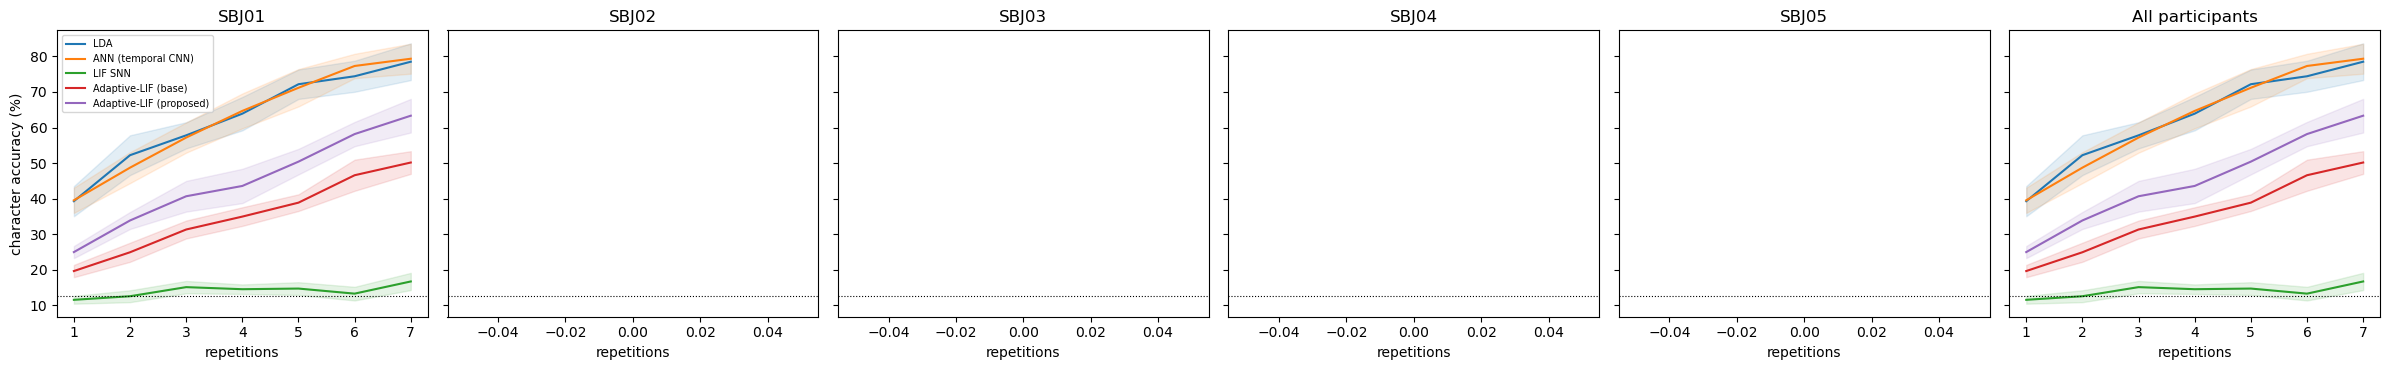

In [11]:
R_FULL = min(b["Rb"] for b in EVID["full"]["blocks"])
REPS = sorted({1, 2, 3, min(5, R_FULL)}); print("Repetitions covered by every block:", R_FULL, "| reported:", REPS)

def acc_curves(blocks):
    rows = []
    for b in blocks:
        ok = (b["cum"].argmax(0) == b["tgt"]).astype(int)
        rows += [(b["subj"], b["sess"], r, int(c)) for r, c in enumerate(ok, 1)]
    return pd.DataFrame(rows, columns=["subj", "sess", "rep", "correct"])

def session_char_table(names):
    out = []
    for m in names:
        cur = acc_curves(EVID[m]["blocks"]); g = cur.groupby(["subj", "sess", "rep"]).correct.mean().unstack("rep")
        fin = pd.DataFrame([(b["subj"], b["sess"], int(b["cum"][:, -1].argmax() == b["tgt"])) for b in EVID[m]["blocks"]], columns=["subj", "sess", "c"]).groupby(["subj", "sess"]).c.mean()
        for (p, s), r in g.iterrows():
            out.append(dict(subject=SUBJECTS[p], session=s + 1, model=m, **{f"acc_r{r_}": r[r_] for r_ in REPS},
                            aurc=r[list(range(1, R_FULL + 1))].mean(), final_acc=fin[(p, s)]))
    return pd.DataFrame(out)
char_df = session_char_table(MAIN_EV); char_df.to_csv(RESULTS / "character_accuracy_per_session.csv", index=False)
LABEL.update({m + "_ua": LABEL[m] + " + uncertainty" for m in ["ann", "lif", "adlif_base", "full"]})
for col, ttl in ((f"acc_r{REPS[-1]}", f"Character accuracy after {REPS[-1]} repetitions"), ("final_acc", "Character accuracy using every available repetition")):
    t = summarise(char_df.rename(columns={col: "v"}), "v", MAIN)
    print(f"\n{ttl} (chance 12.5%), mean [95% CI]\n", t.to_string())
    t.to_csv(RESULTS / f"table_{col}_per_participant.csv")
cmp9 = U.family_vs(char_df, "aurc", "full", ref_models); cmp9.to_csv(RESULTS / "stats_aurc_proposed_vs_others.csv", index=False)
print("\nAURC, proposed minus reference (paired over held-out sessions, Holm):\n", cmp9.round(4).to_string(index=False))

fig, ax = plt.subplots(1, len(SUBJECTS) + 1, figsize=(4 * (len(SUBJECTS) + 1), 3.8), sharey=True)
for j, m in enumerate(MAIN):
    cur = acc_curves(EVID[m]["blocks"]); n_at = cur.groupby("rep").size(); rmax = int(n_at[n_at >= 0.5 * n_at.iloc[0]].index.max())
    for p in range(len(SUBJECTS) + 1):
        d = cur if p == len(SUBJECTS) else cur[cur.subj == p]
        g = d.groupby(["subj", "sess", "rep"]).correct.mean().unstack(["subj", "sess"]).loc[1:rmax]   # one column per held-out session
        mu, se = g.mean(1), g.std(1, ddof=1) / np.sqrt(g.shape[1]) if g.shape[1] > 1 else 0 * g.mean(1)
        ax[p].plot(mu.index, mu.values * 100, "-", color=f"C{j}", label=LABEL[m] if p == 0 else None); ax[p].fill_between(mu.index, (mu - se) * 100, (mu + se) * 100, color=f"C{j}", alpha=0.12)
for p, a in enumerate(ax):
    a.axhline(100 / N_OBJ, color="k", ls=":", lw=0.8); a.set_xlabel("repetitions"); a.set_title(SUBJECTS[p] if p < len(SUBJECTS) else "All participants")
ax[0].set_ylabel("character accuracy (%)"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(RESULTS / "fig2_speller_accuracy.png", dpi=200); plt.show()

## 10. Drift-diffusion model of the accumulated evidence (framework unchanged)

One repetition is one discrete accumulation step; the cumulative unit-noise evidence of a (block, object) trial is compared with boundaries at `+-THETA`; the DDM (target drift, non-target drift, boundary) is fitted by maximum likelihood on the first-passage distribution. The functions below are the ones of the SBJ01 study. Only the inputs changed: held-out evidence, an explicit `valid` mask instead of zero-filling, and one fit per participant, session and method.

In [12]:
def ddm_tables(v, a, rmax, n=121):
    # exact first-passage masses of a discrete-time Gaussian random walk (step ~ N(v, 1)), absorbing at +-a
    h = 2 * a / n
    edges = -a + h * np.arange(n + 1); centers = (edges[:-1] + edges[1:]) / 2
    cdf = norm.cdf(edges[None, :] - centers[:, None] - v)
    Tm = np.diff(cdf, axis=1); up = 1 - cdf[:, -1]; lo = cdf[:, 0]
    p = np.zeros(n); p[n // 2] = 1.0
    ups, los, surv, pos = [], [], [], []
    for _ in range(rmax):
        ups.append(p @ up); los.append(p @ lo); p = p @ Tm
        surv.append(p.sum()); pos.append(p[centers > 0].sum())
    return np.array(ups), np.array(los), np.array(surv), np.array(pos)

def run_policy(cum, R, theta):
    n = len(R); choice = np.zeros(n, int); decision = np.zeros(n, int); rt = R.copy()
    for i in range(n):
        c = cum[i, :R[i]]
        hit = np.where(np.abs(c) >= theta)[0]
        if len(hit):
            choice[i] = decision[i] = 1 if c[hit[0]] > 0 else -1; rt[i] = hit[0] + 1
        else:
            decision[i] = 1 if c[-1] > 0 else -1
    return choice, decision, rt

def fit_ddm(y, choice, rt, v0, a0, n=121):
    rmax = int(rt.max())
    def nll(p):
        vT, vN, la = p; a = np.exp(la); ll = 0.0
        for c, v in ((1, vT), (0, vN)):
            up, lo, sv, _ = ddm_tables(v, a, rmax, n)
            m = y == c; ch = choice[m]; r = rt[m] - 1
            pr = np.where(ch == 1, up[r], np.where(ch == -1, lo[r], sv[r]))
            ll += np.log(np.maximum(pr, 1e-12)).sum()
        return -ll
    r = minimize(nll, [v0[0], v0[1], np.log(a0)], method="Nelder-Mead", options=dict(xatol=1e-3, fatol=1e-3, maxiter=600))
    return r.x[0], r.x[1], float(np.exp(r.x[2])), float(r.fun)

def ddm_predict(vT, vN, a, R, y, n=121):
    rmax = int(R.max()); out = {}
    for c, v in ((1, vT), (0, vN)):
        up, lo, sv, pos = ddm_tables(v, a, rmax, n)
        rr = np.arange(1, rmax + 1); m = (y == c); i = R[m] - 1
        p_up = np.cumsum(up)[i] + pos[i]                       # declared "target", timeouts decided by sign
        ert = np.cumsum(rr * (up + lo))[i] + R[m] * sv[i]
        out[c] = (p_up.mean(), ert.mean(), m.sum())
    hit, rt1, n1 = out[1]; fa, rt0, n0 = out[0]
    return dict(hit=hit, fa=fa, bacc=(hit + 1 - fa) / 2, rt=(rt1 * n1 + rt0 * n0) / (n1 + n0))

def empirical(cum, R, y, theta):
    ch, dec, rt = run_policy(cum, R, theta)
    hit = (dec[y == 1] == 1).mean(); fa = (dec[y == 0] == 1).mean()
    return dict(hit=hit, fa=fa, bacc=(hit + 1 - fa) / 2, rt=rt.mean(), timeout=(ch == 0).mean()), ch, dec, rt

# ---- parameter recovery self-test: simulate a known DDM and check the fit recovers it ----
_rs = np.random.default_rng(0); _n = 1500; _y = (np.arange(_n) % 4 == 0).astype(int)
_R = np.full(_n, 8); _cum = np.cumsum(_rs.normal(np.where(_y == 1, 0.45, -0.30)[:, None], 1.0, (_n, 8)), axis=1)
_ch, _dec, _rt = run_policy(_cum, _R, 2.0)
_fit = fit_ddm(_y, _ch, _rt, (0.2, -0.2), 1.5)
print(f"Recovery test (true vT=0.45, vN=-0.30, a=2.0): fitted vT={_fit[0]:.2f}, vN={_fit[1]:.2f}, a={_fit[2]:.2f}")

Recovery test (true vT=0.45, vN=-0.30, a=2.0): fitted vT=0.43, vN=-0.27, a=2.06


DDM fit per participant (mean over held-out sessions), THETA = 3.0
                    dprime  v_target  v_nontarget   a_fit  a_policy  emp_rt  pred_rt
method     subject                                                                  
adlif_base SBJ01     0.529     0.191       -0.224   5.300     5.794   7.954    7.947
ann        SBJ01     1.176     0.399       -0.518   2.378     2.575   4.738    4.722
full       SBJ01     0.783     0.308       -0.365   3.709     3.869   6.774    6.769
full_ua    SBJ01     0.605     0.322       -0.356   5.013     5.355   7.448    7.424
lda        SBJ01     1.116     0.390       -0.496   2.532     2.707   4.986    4.966
lif        SBJ01     0.062    -0.012       -0.043  91.189    81.015   8.443    8.443

Pooled over all held-out sessions (mean, SD in brackets):
  LDA        : v_target 0.390 (0.200) | v_nontarget -0.496 (0.091) | a 2.53 (policy 2.71) | decision time 4.99 reps
  ANN        : v_target 0.399 (0.202) | v_nontarget -0.518 (0.090) | a 2.38 (p

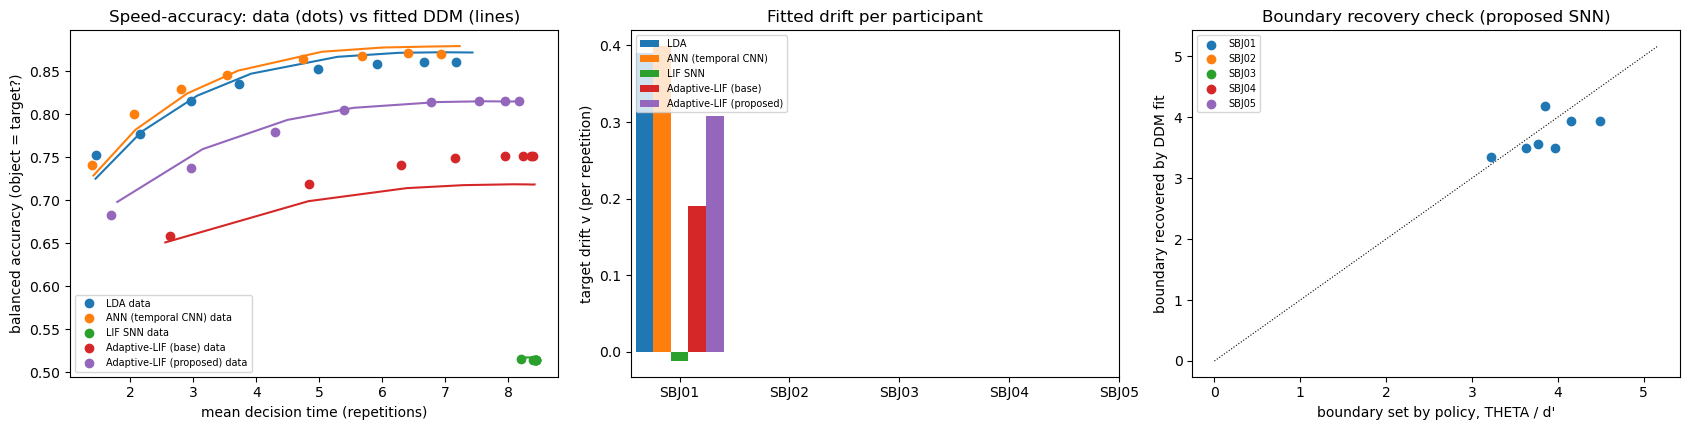

In [13]:
DDM_STREAMS = ["lda", "ann", "lif", "adlif_base", "full", "full_ua"]
ddm_rows, sweep_rows = [], []
for m in DDM_STREAMS:
    tr = EVID[m]["trials"]
    for key in run_keys:
        msk = (tr["subj"] == key[0]) & (tr["sess"] == key[1])
        inc, valid, R, y = tr["inc"][msk], tr["valid"][msk], tr["R"][msk], tr["y"][msk]
        d = EVID[m]["dprime"][key]
        cum = np.cumsum(np.where(valid, inc, 0.0), axis=1)                    # padding contributes nothing and is never read (cum[i, :R[i]])
        emp, ch, dec, rt = empirical(cum, R, y, THETA_REF)
        w = np.where(valid, inc, 0.0) / d                                      # unit-noise increments
        v_mom = (w[valid & (y == 1)[:, None]].mean(), w[valid & (y == 0)[:, None]].mean())
        vT, vN, a_fit, nll = fit_ddm(y, ch, rt, v_mom, THETA_REF / d)
        pred = ddm_predict(vT, vN, a_fit, R, y)
        ddm_rows.append(dict(method=m, subject=SUBJECTS[key[0]], session=key[1] + 1, dprime=d, v_target=vT, v_nontarget=vN, a_fit=a_fit,
                             a_policy=THETA_REF / d, v_moment_T=v_mom[0], v_moment_N=v_mom[1],
                             emp_hit=emp["hit"], pred_hit=pred["hit"], emp_fa=emp["fa"], pred_fa=pred["fa"],
                             emp_rt=emp["rt"], pred_rt=pred["rt"], timeout=emp["timeout"], nll=nll, n_trials=len(y)))
        for th in THETAS:                                                       # speed-accuracy sweep, boundary only changes
            e, _, _, _ = empirical(cum, R, y, th); p = ddm_predict(vT, vN, th / d, R, y)
            sweep_rows.append(dict(method=m, subject=SUBJECTS[key[0]], session=key[1] + 1, theta=th, emp_bacc=e["bacc"], emp_rt=e["rt"],
                                   pred_bacc=p["bacc"], pred_rt=p["rt"]))
ddm_df, sweep_df = pd.DataFrame(ddm_rows), pd.DataFrame(sweep_rows)
ddm_df.to_csv(RESULTS / "ddm_fits_per_session.csv", index=False); sweep_df.to_csv(RESULTS / "speed_accuracy_sweep.csv", index=False)

print("DDM fit per participant (mean over held-out sessions), THETA =", THETA_REF)
agg = ddm_df.groupby(["method", "subject"])[["dprime", "v_target", "v_nontarget", "a_fit", "a_policy", "emp_rt", "pred_rt"]].mean().round(3)
print(agg.to_string())
print("\nPooled over all held-out sessions (mean, SD in brackets):")
for m in DDM_STREAMS:
    g = ddm_df[ddm_df.method == m]
    print(f"  {m.upper():11s}: v_target {g.v_target.mean():.3f} ({g.v_target.std(ddof=1):.3f}) | v_nontarget {g.v_nontarget.mean():.3f} "
          f"({g.v_nontarget.std(ddof=1):.3f}) | a {g.a_fit.mean():.2f} (policy {g.a_policy.mean():.2f}) | decision time {g.emp_rt.mean():.2f} reps")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for j, m in enumerate(["lda", "ann", "lif", "adlif_base", "full"]):
    g = sweep_df[sweep_df.method == m].groupby("theta")[["emp_rt", "emp_bacc", "pred_rt", "pred_bacc"]].mean()
    ax[0].plot(g.emp_rt, g.emp_bacc, "o", color=f"C{j}", label=f"{LABEL[m]} data"); ax[0].plot(g.pred_rt, g.pred_bacc, "-", color=f"C{j}")
ax[0].set_xlabel("mean decision time (repetitions)"); ax[0].set_ylabel("balanced accuracy (object = target?)"); ax[0].set_title("Speed-accuracy: data (dots) vs fitted DDM (lines)"); ax[0].legend(fontsize=7)
xs = np.arange(len(SUBJECTS)); w = 0.16
for j, m in enumerate(["lda", "ann", "lif", "adlif_base", "full"]):
    g = ddm_df[ddm_df.method == m].groupby("subject").v_target.mean().reindex(SUBJECTS)
    ax[1].bar(xs + (j - 2) * w, g.values, w, color=f"C{j}", label=LABEL[m])
ax[1].set_xticks(xs); ax[1].set_xticklabels(SUBJECTS); ax[1].set_ylabel("target drift v (per repetition)"); ax[1].set_title("Fitted drift per participant"); ax[1].legend(fontsize=7)
g = ddm_df[ddm_df.method == "full"]
for s in SUBJECTS: ax[2].scatter(g[g.subject == s].a_policy, g[g.subject == s].a_fit, label=s)
lim = [0, max(g.a_policy.max(), g.a_fit.max()) * 1.15]; ax[2].plot(lim, lim, "k:", lw=0.8)
ax[2].set_xlabel("boundary set by policy, THETA / d'"); ax[2].set_ylabel("boundary recovered by DDM fit"); ax[2].set_title("Boundary recovery check (proposed SNN)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS / "fig3_ddm.png", dpi=200); plt.show()

## 11. Does the block-level drift predict whether the block is decided correctly?

To avoid circularity, drift is estimated from the **odd** repetitions of a block (mean evidence for the true target object, and its margin over the other objects), and correctness comes from the **even** repetitions only. Reported per participant and pooled.

In [14]:
def block_level(blocks):
    rows = []
    for b in blocks:
        if b["Rb"] < 4: continue
        odd, even, tgt = b["inc"][:, 0::2], b["inc"][:, 1::2], b["tgt"]
        rows.append(dict(subject=SUBJECTS[b["subj"]], drift=odd[tgt].mean(), margin=odd[tgt].mean() - np.delete(odd, tgt, axis=0).mean(),
                         correct=int(np.argmax(even.sum(1)) == tgt)))
    return pd.DataFrame(rows)

bl_rows = []
for m in MAIN:
    bl = block_level(EVID[m]["blocks"])
    for subj, g in [("Pooled", bl)] + list(bl.groupby("subject")):
        ok = g.correct.nunique() == 2
        bl_rows.append(dict(method=m, subject=subj, blocks=len(g), even_rep_accuracy=g.correct.mean(),
                            auc_margin=roc_auc_score(g.correct, g.margin) if ok else np.nan,
                            drift_correct=g[g.correct == 1].drift.mean(), drift_incorrect=g[g.correct == 0].drift.mean()))
bl_df = pd.DataFrame(bl_rows); bl_df.to_csv(RESULTS / "block_level_crosscheck.csv", index=False)
print(bl_df[bl_df.subject == "Pooled"].round(3).to_string(index=False))
print("\nProposed SNN, per participant:\n", bl_df[(bl_df.method == "full") & (bl_df.subject != "Pooled")].round(3).to_string(index=False))

    method subject  blocks  even_rep_accuracy  auc_margin  drift_correct  drift_incorrect
       lda  Pooled     452              0.624       0.678          0.802            0.304
       ann  Pooled     452              0.646       0.682          0.823            0.262
       lif  Pooled     452              0.122       0.490         -0.015            0.001
adlif_base  Pooled     452              0.383       0.543          0.167            0.120
      full  Pooled     452              0.491       0.575          0.342            0.225

Proposed SNN, per participant:
 method subject  blocks  even_rep_accuracy  auc_margin  drift_correct  drift_incorrect
  full   SBJ01     452              0.491       0.575          0.342            0.225


## 12. Ablation study: does each proposed SNN component help?

All variants below are trained with the **same seed (0)**, the same folds, the same calibration and the same decoding, so differences come from the architecture only. *Additive*: each component is added to the base Adaptive-LIF. *Leave-one-out*: each component is removed from the proposed model (`full_no_ad` replaces the adaptive neurons by plain LIF neurons). Differences are paired over held-out sessions; CIs come from the hierarchical bootstrap and p-values are Wilcoxon signed-rank tests with Holm correction inside each family.

Ablation (seed 0), pooled mean [95% CI] and AUC per participant
                 variant                  auc                 aurc  SBJ01  SBJ02  SBJ03  SBJ04  SBJ05
                LIF SNN 0.519 [0.510, 0.527] 0.136 [0.115, 0.156]  0.519    NaN    NaN    NaN    NaN
    Adaptive-LIF (base) 0.647 [0.632, 0.662] 0.299 [0.264, 0.334]  0.647    NaN    NaN    NaN    NaN
Adaptive-LIF (proposed) 0.696 [0.673, 0.719] 0.387 [0.333, 0.444]  0.696    NaN    NaN    NaN    NaN

Paired differences (first model minus reference), Holm inside each family:
metric            family      model        ref  mean_diff  ci_lo  ci_hi  p_wilcoxon  p_holm  participants_better
   auc  additive vs base       full adlif_base     0.0491 0.0377 0.0600      0.0156  0.0156                    1
   auc adaptation vs LIF adlif_base        lif     0.1281 0.1108 0.1493      0.0156  0.0156                    1
  aurc  additive vs base       full adlif_base     0.0876 0.0602 0.1144      0.0156  0.0156                    1
  a

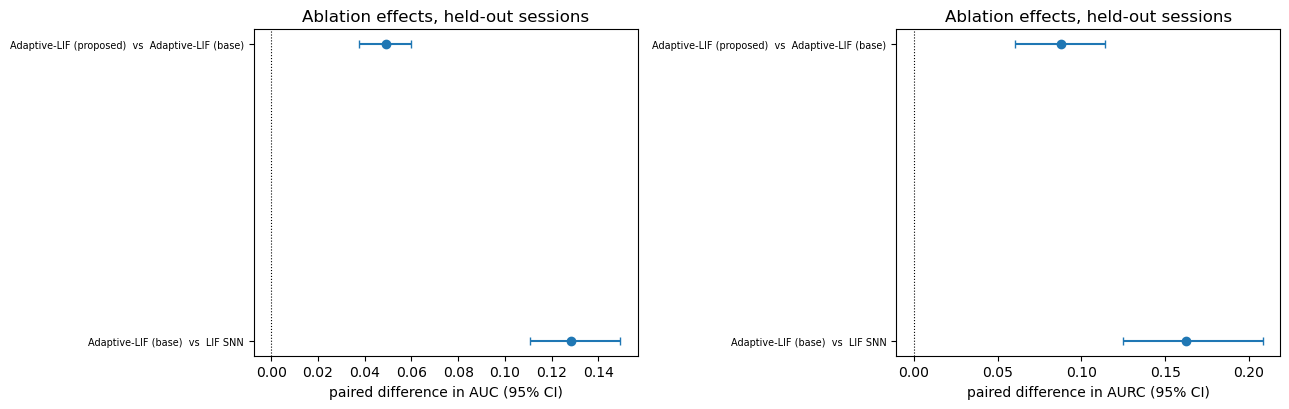

In [15]:
ABL = [m for m in VARIANTS if m in NN_MODELS]
ABL_S = [m + "@s0" for m in ABL] + ["ann@s0"]
for n in ABL_S: get_evidence(n)
strip = lambda d: d.assign(model=d.model.str.replace("@s0", "", regex=False))
abl_char = strip(session_char_table(ABL_S))
abl_auc = pd.DataFrame([dict(subject=SUBJECTS[k[0]], session=k[1] + 1, model=n.replace("@s0", ""),
                             auc=roc_auc_score(y_all[folds[k]["te"]], score[n][folds[k]["te"]])) for n in ABL_S for k in run_keys])
abl = abl_auc.merge(abl_char[["subject", "session", "model", "aurc", f"acc_r{REPS[-1]}", "final_acc"]], on=["subject", "session", "model"])
abl.to_csv(RESULTS / "ablation_per_session.csv", index=False)

rows = []
for m in ABL:
    g = abl[abl.model == m]
    rows.append(dict(variant=LABEL[m], auc="%.3f [%.3f, %.3f]" % U.two_level_bootstrap(g, "auc"), aurc="%.3f [%.3f, %.3f]" % U.two_level_bootstrap(g, "aurc"),
                     **{s: round(g[g.subject == s].auc.mean(), 3) for s in SUBJECTS}))
abl_tab = pd.DataFrame(rows); abl_tab.to_csv(RESULTS / "table_ablation.csv", index=False)
print("Ablation (seed 0), pooled mean [95% CI] and AUC per participant\n", abl_tab.to_string(index=False))

add_refs = [m for m in ["ad_hetero", "ad_ms", "ad_tel", "full"] if m in ABL]
loo_refs = [m for m in ["full_no_het", "full_no_ms", "full_no_tel", "full_no_ad"] if m in ABL]
stat_rows = []
for metric in ("auc", "aurc"):
    for fam, new_list, ref_list in (("additive vs base", add_refs, ["adlif_base"]), ("proposed vs leave-one-out", ["full"], loo_refs), ("adaptation vs LIF", ["adlif_base"], ["lif"])):
        for new in new_list:
            for ref in ref_list:
                if new != ref: stat_rows.append(U.family_vs(abl, metric, new, [ref]).assign(metric=metric, family=fam))
abl_stats = pd.concat(stat_rows, ignore_index=True)
for (metric, fam), g in abl_stats.groupby(["metric", "family"]): abl_stats.loc[g.index, "p_holm"] = U.holm(g.p_wilcoxon.values)
abl_stats.to_csv(RESULTS / "stats_ablation.csv", index=False)
print("\nPaired differences (first model minus reference), Holm inside each family:")
print(abl_stats[["metric", "family", "model", "ref", "mean_diff", "ci_lo", "ci_hi", "p_wilcoxon", "p_holm", "participants_better"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, metric in zip(ax, ("auc", "aurc")):
    g = abl_stats[abl_stats.metric == metric].reset_index(drop=True); y_pos = np.arange(len(g))[::-1]
    a.errorbar(g.mean_diff, y_pos, xerr=[g.mean_diff - g.ci_lo, g.ci_hi - g.mean_diff], fmt="o", capsize=3)
    a.set_yticks(y_pos); a.set_yticklabels([f"{LABEL[n]}  vs  {LABEL[r]}" for n, r in zip(g.model, g.ref)], fontsize=7); a.axvline(0, color="k", lw=0.8, ls=":")
    a.set_xlabel(f"paired difference in {metric.upper()} (95% CI)"); a.set_title("Ablation effects, held-out sessions")
plt.tight_layout(); plt.savefig(RESULTS / "fig4_ablation.png", dpi=200); plt.show()

## 13. Uncertainty-aware sequential decoding and adaptive stopping

Three decoders per score stream, all with settings chosen on the calibration blocks of the fold:

* **fixed**: always use the same number of repetitions (the one with the best information rate on the calibration blocks)
* **adaptive**: stop as soon as the posterior of the best object, `softmax` of the cumulative evidence over the 8 objects, reaches `1 - alpha`; `alpha` is the value that maximises the information rate (bits per repetition, Wolpaw) on the calibration blocks
* **adaptive + uncertainty**: the same stopping rule on the uncertainty-aware evidence (`*_ua`), where uncertain flashes are down-weighted

Test blocks never choose `alpha`, the number of repetitions or `kappa`. A block that never reaches the threshold is decided at its last repetition.

Decoding rules, mean over held-out sessions (alpha / number of repetitions chosen on calibration blocks):
                                model  adaptive_acc  adaptive_reps  adaptive_bits_per_rep  fixed_acc  fixed_reps  fixed_bits_per_rep  ddm_decision_time
                                  LDA         0.590          2.661                  0.355      0.473       2.000               0.322              4.986
                   ANN (temporal CNN)         0.652          3.641                  0.326      0.507       2.143               0.337              4.738
     ANN (temporal CNN) + uncertainty         0.672          3.705                  0.337      0.459       1.571               0.339                NaN
                              LIF SNN         0.159          8.443                  0.003      0.129       1.857               0.003              8.443
                LIF SNN + uncertainty         0.149          8.443                  0.002      0.139       1.857               0.003  

e:\IIT KGP IEEE\Analysis\p300_utils.py:22: RuntimeWarning: Mean of empty slice.
  m = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
e:\IIT KGP IEEE\Analysis\p300_utils.py:23: RuntimeWarning: Mean of empty slice.
  return float(x.mean()), *np.percentile(m, [2.5, 97.5])
c:\Users\abhia\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


                         LDA    ANN (temporal CNN) ANN (temporal CNN) + uncertainty               LIF SNN LIF SNN + uncertainty   Adaptive-LIF (base) Adaptive-LIF (base) + uncertainty Adaptive-LIF (proposed) Adaptive-LIF (proposed) + uncertainty
SBJ01   0.355 [0.246, 0.455]  0.326 [0.232, 0.418]             0.337 [0.233, 0.433]  0.003 [0.000, 0.008]  0.002 [0.000, 0.006]  0.085 [0.068, 0.111]              0.082 [0.064, 0.110]    0.148 [0.096, 0.206]                  0.151 [0.100, 0.206]
SBJ02         nan [nan, nan]        nan [nan, nan]                   nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]                    nan [nan, nan]          nan [nan, nan]                        nan [nan, nan]
SBJ03         nan [nan, nan]        nan [nan, nan]                   nan [nan, nan]        nan [nan, nan]        nan [nan, nan]        nan [nan, nan]                    nan [nan, nan]          nan [nan, nan]                        nan [nan, nan]
SBJ04         na

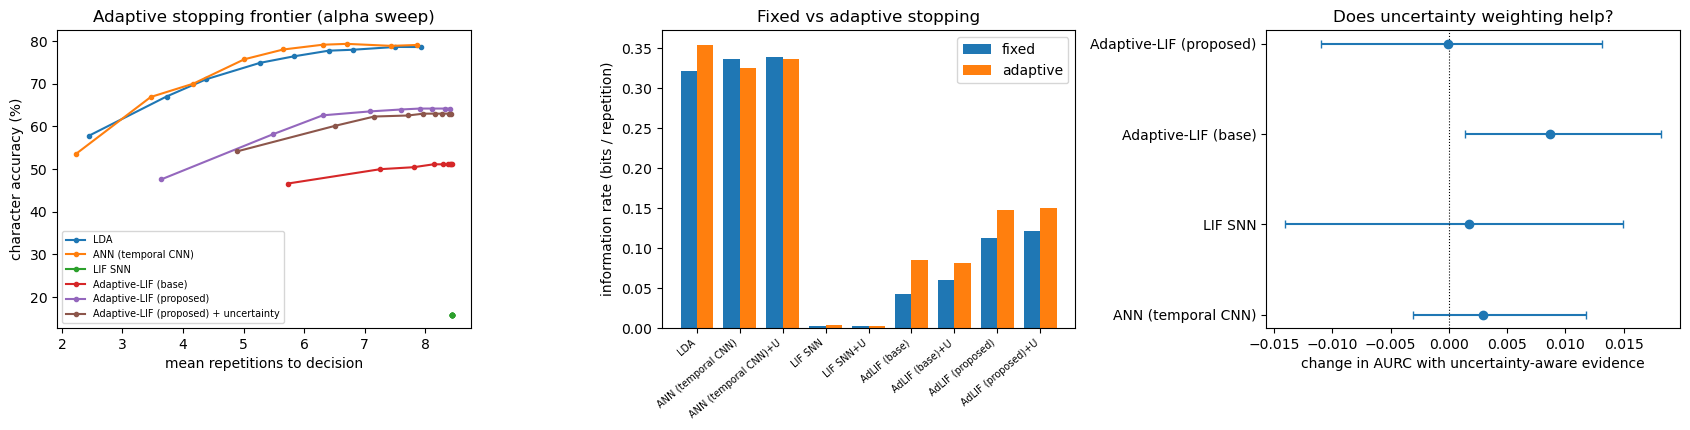

In [16]:
ALPHAS = [0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 1e-3, 1e-4]
def wolpaw_bits(P, N=N_OBJ):
    if P <= 1 / N: return 0.0
    if P >= 1: return math.log2(N)
    return math.log2(N) + P * math.log2(P) + (1 - P) * math.log2((1 - P) / (N - 1))

def stop_adaptive(b, alpha):
    c = b["cum"]; post = np.exp(c - c.max(0)); post /= post.sum(0)
    hit = np.flatnonzero(post.max(0) >= 1 - alpha); r = int(hit[0]) if len(hit) else b["Rb"] - 1
    return int(c[:, r].argmax() == b["tgt"]), r + 1

def stop_fixed(b, r):
    r = min(r, b["Rb"]); return int(b["cum"][:, r - 1].argmax() == b["tgt"]), r

def rate_of(blocks, rule):
    res = np.array([rule(b) for b in blocks]); acc, reps = res[:, 0].mean(), res[:, 1].mean()
    return acc, reps, wolpaw_bits(acc) / reps

def cal_blocks(name, key):
    return blocks_of(build_trials(folds[key]["ca"], EVID[name]["llr_cal"][key]))

STOP_STREAMS = ["lda", "ann", "ann_ua", "lif", "lif_ua", "adlif_base", "adlif_base_ua", "full", "full_ua"]
stop_rows, frontier = [], []
for name in STOP_STREAMS:
    test_blocks = {}
    for b in EVID[name]["blocks"]: test_blocks.setdefault((b["subj"], b["sess"]), []).append(b)
    for key in run_keys:
        cb = cal_blocks(name, key); tb = test_blocks[key]
        alpha = max(ALPHAS, key=lambda a: rate_of(cb, lambda b: stop_adaptive(b, a))[2])
        r_fix = max(range(1, R_FULL + 1), key=lambda r: rate_of(cb, lambda b: stop_fixed(b, r))[2])
        for rule, fn in (("adaptive", lambda b: stop_adaptive(b, alpha)), ("fixed", lambda b: stop_fixed(b, r_fix))):
            acc, reps, bpr = rate_of(tb, fn)
            stop_rows.append(dict(model=name, subject=SUBJECTS[key[0]], session=key[1] + 1, rule=rule, alpha=alpha if rule == "adaptive" else np.nan,
                                  fixed_reps=r_fix if rule == "fixed" else np.nan, accuracy=acc, mean_reps=reps, bits_per_rep=bpr))
        for a in ALPHAS:                                              # full frontier on the held-out session, for plotting only
            acc, reps, bpr = rate_of(tb, lambda b: stop_adaptive(b, a)); frontier.append(dict(model=name, subject=SUBJECTS[key[0]], session=key[1] + 1, alpha=a, accuracy=acc, mean_reps=reps))
stop_df = pd.DataFrame(stop_rows); stop_df.to_csv(RESULTS / "stopping_per_session.csv", index=False)
front_df = pd.DataFrame(frontier); front_df.to_csv(RESULTS / "stopping_frontier.csv", index=False)

ad = stop_df[stop_df.rule == "adaptive"]; fx = stop_df[stop_df.rule == "fixed"]
summ = []
for name in STOP_STREAMS:
    a, f_ = ad[ad.model == name], fx[fx.model == name]
    summ.append(dict(model=LABEL[name], adaptive_acc=a.accuracy.mean(), adaptive_reps=a.mean_reps.mean(), adaptive_bits_per_rep=a.bits_per_rep.mean(),
                     fixed_acc=f_.accuracy.mean(), fixed_reps=f_.mean_reps.mean(), fixed_bits_per_rep=f_.bits_per_rep.mean(),
                     ddm_decision_time=ddm_df[ddm_df.method == name].emp_rt.mean() if name in DDM_STREAMS else np.nan))
stop_tab = pd.DataFrame(summ); stop_tab.to_csv(RESULTS / "table_stopping.csv", index=False)
print("Decoding rules, mean over held-out sessions (alpha / number of repetitions chosen on calibration blocks):")
print(stop_tab.round(3).to_string(index=False))
print("\nAdaptive stopping, bits per repetition, per participant (mean [95% CI over sessions]):")
print(summarise(ad.rename(columns={"bits_per_rep": "v"}), "v", STOP_STREAMS).to_string())

ad_b = ad.rename(columns={"bits_per_rep": "bpr"})
cmp13 = U.family_vs(ad_b, "bpr", "full_ua", ["lda", "ann", "lif", "adlif_base", "full"]); cmp13.to_csv(RESULTS / "stats_stopping_proposed_vs_others.csv", index=False)
print("\nAdaptive stopping information rate, proposed + uncertainty minus reference:\n", cmp13.round(4).to_string(index=False))
ua_rows = []
for m in ["ann", "lif", "adlif_base", "full"]:
    ua_rows.append(U.paired_table(char_df, "aurc", ref=m, models=[m + "_ua"]).assign(metric="aurc"))
    ua_rows.append(U.paired_table(ad_b, "bpr", ref=m, models=[m + "_ua"]).assign(metric="bits_per_rep(adaptive)"))
ua_stats = pd.concat(ua_rows, ignore_index=True); ua_stats.to_csv(RESULTS / "stats_uncertainty_effect.csv", index=False)
print("\nEffect of the uncertainty-aware evidence (ua minus plain), per model:\n", ua_stats[["metric", "model", "ref", "mean_diff", "ci_lo", "ci_hi", "p_wilcoxon"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for j, name in enumerate(["lda", "ann", "lif", "adlif_base", "full", "full_ua"]):
    g = front_df[front_df.model == name].groupby("alpha")[["mean_reps", "accuracy"]].mean().sort_index(ascending=False)
    ax[0].plot(g.mean_reps, g.accuracy * 100, "-o", ms=3, color=f"C{j}", label=LABEL[name])
ax[0].set_xlabel("mean repetitions to decision"); ax[0].set_ylabel("character accuracy (%)"); ax[0].set_title("Adaptive stopping frontier (alpha sweep)"); ax[0].legend(fontsize=7)
xs = np.arange(len(STOP_STREAMS))
for j, (rule, d) in enumerate((("fixed", fx), ("adaptive", ad))):
    mu = [d[d.model == m].bits_per_rep.mean() for m in STOP_STREAMS]
    ax[1].bar(xs + (j - 0.5) * 0.38, mu, 0.38, label=rule)
ax[1].set_xticks(xs); ax[1].set_xticklabels([LABEL[m].replace(" + uncertainty", "+U").replace("Adaptive-LIF", "AdLIF") for m in STOP_STREAMS], rotation=40, ha="right", fontsize=7)
ax[1].set_ylabel("information rate (bits / repetition)"); ax[1].set_title("Fixed vs adaptive stopping"); ax[1].legend()
g = ua_stats[ua_stats.metric == "aurc"].reset_index(drop=True)
ax[2].errorbar(g.mean_diff, np.arange(len(g)), xerr=[g.mean_diff - g.ci_lo, g.ci_hi - g.mean_diff], fmt="o", capsize=3)
ax[2].set_yticks(np.arange(len(g))); ax[2].set_yticklabels([LABEL[r] for r in g.ref]); ax[2].axvline(0, color="k", lw=0.8, ls=":")
ax[2].set_xlabel("change in AURC with uncertainty-aware evidence"); ax[2].set_title("Does uncertainty weighting help?")
plt.tight_layout(); plt.savefig(RESULTS / "fig5_stopping_uncertainty.png", dpi=200); plt.show()

## 14. Robustness to corrupted held-out input

The trained models (seed 0, no retraining) score the held-out epochs after test-time corruption of the standardised input: additive Gaussian noise (0.5, 1 and 2 SD), loss of 1 or 2 channels, and random latency jitter of +-32 ms or +-64 ms per epoch. The ranking of methods is judged on the average AUC over all corruptions and on how much of the clean AUC is kept.

                         clean noise_0.5 noise_1.0 noise_2.0 drop_1ch drop_2ch jitter_2bins jitter_4bins mean over corruptions AUC retained
LDA                      0.780     0.607     0.557     0.529    0.702    0.687        0.732        0.623  0.634 [0.610, 0.656]        0.814
ANN (temporal CNN)       0.784     0.624     0.568     0.535    0.717    0.684        0.755        0.669  0.650 [0.628, 0.672]        0.831
LIF SNN                  0.519     0.522     0.521     0.513    0.512    0.517        0.516        0.515  0.517 [0.511, 0.522]        0.995
Adaptive-LIF (base)      0.647     0.635     0.606     0.567    0.641    0.626        0.637        0.613  0.618 [0.604, 0.633]        0.955
Adaptive-LIF (proposed)  0.696     0.653     0.610     0.564    0.689    0.657        0.679        0.639  0.642 [0.626, 0.659]        0.922

Mean AUC over corruptions, proposed minus reference:
 model        ref  n_sessions  mean_diff   ci_lo  ci_hi  median_diff  p_wilcoxon  participants_better  n_p

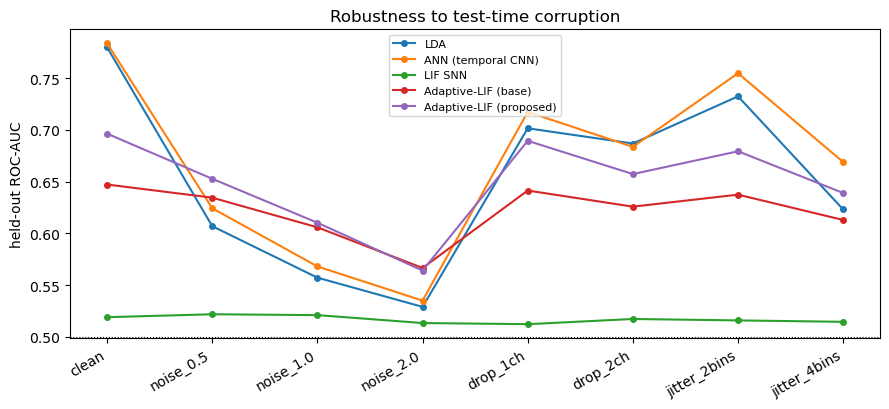

In [17]:
rob = pd.DataFrame(rob_rows); rob["subject"] = [SUBJECTS[k[0]] for k in rob.key]; rob["session"] = [k[1] + 1 for k in rob.key]
rob = rob.drop(columns="key"); rob.to_csv(RESULTS / "robustness_per_session.csv", index=False)
clean = rob[rob.perturbation == "clean"].set_index(["model", "subject", "session"]).auc
rob["retained"] = [a / clean[(m, s, k)] for m, s, k, a in zip(rob.model, rob.subject, rob.session, rob.auc)]
pert_names = [p for p in PERT]
rob_s = rob[rob.perturbation.isin(pert_names)].groupby(["model", "subject", "session"])[["auc", "retained"]].mean().reset_index()
rob_tab = pd.DataFrame({LABEL[m]: {p: "%.3f" % rob[(rob.model == m) & (rob.perturbation == p)].auc.mean() for p in ["clean"] + pert_names} for m in MAIN}).T
rob_tab["mean over corruptions"] = [ "%.3f [%.3f, %.3f]" % U.two_level_bootstrap(rob_s[rob_s.model == m], "auc") for m in MAIN]
rob_tab["AUC retained"] = ["%.3f" % rob_s[rob_s.model == m].retained.mean() for m in MAIN]
rob_tab.to_csv(RESULTS / "table_robustness.csv"); print(rob_tab.to_string())
cmp14 = U.family_vs(rob_s, "auc", "full", ref_models); cmp14.to_csv(RESULTS / "stats_robustness_proposed_vs_others.csv", index=False)
print("\nMean AUC over corruptions, proposed minus reference:\n", cmp14.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4.2)); xs = np.arange(len(pert_names) + 1)
for j, m in enumerate(MAIN):
    ax.plot(xs, [rob[(rob.model == m) & (rob.perturbation == p)].auc.mean() for p in ["clean"] + pert_names], "-o", ms=4, label=LABEL[m])
ax.set_xticks(xs); ax.set_xticklabels(["clean"] + pert_names, rotation=30, ha="right"); ax.axhline(0.5, color="k", ls=":", lw=0.8)
ax.set_ylabel("held-out ROC-AUC"); ax.set_title("Robustness to test-time corruption"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(RESULTS / "fig6_robustness.png", dpi=200); plt.show()

## 15. Computational cost

Measured: trainable parameters, training time per model, inference time per epoch (on this machine, CPU batch of 1 and the training device in batches). **Estimated, not measured on neuromorphic hardware:** operation counts and energy. For the SNNs the first layer sees analog input (multiply-accumulates, MAC) and later layers only add on spikes (accumulates, AC, using the measured firing rates); the ANN uses MACs everywhere. Energy uses the common 45 nm figures of 4.6 pJ per 32-bit MAC and 0.9 pJ per AC; membrane-state updates are ignored for both. These numbers show the potential of sparse spiking activity, not a hardware result.

In [18]:
def op_counts(m, r1, r2):
    T = T_STEPS
    if m == "ann":
        mod = build_model("ann"); c1, c2 = mod.c1.out_channels, mod.c2.out_channels
        return T * c1 * N_CH * 7 + (T // 2) * c2 * c1 * 5 + c2, 0
    k = 3 if VARIANTS[m]["ms"] else 1
    return T * H1 * N_CH * k, r1 * T * H1 * H2 + r2 * T * H2

def time_infer_cpu(model, reps=40):
    model.eval(); x = torch.randn(1, T_STEPS, N_CH)
    with torch.no_grad():
        for _ in range(3): model(x)
        t0 = time.time()
        for _ in range(reps): model(x)
    return 1000 * (time.time() - t0) / reps

cost_rows = []
for m in MAIN_NN:
    g = seed_df[seed_df.model == m]; r1, r2 = g.rate1.mean(), g.rate2.mean()
    macs, acs = op_counts(m, 0 if np.isnan(r1) else r1, 0 if np.isnan(r2) else r2)
    mod = build_model(m)
    cost_rows.append(dict(model=LABEL[m], params=n_params(mod), rate_L1=r1, rate_L2=r2, MACs=macs, ACs=acs, est_energy_nJ=U.energy_pj(macs, acs) / 1000,
                          cpu_ms_per_epoch_batch1=time_infer_cpu(mod), device_ms_per_epoch=g.infer_ms.mean(), train_s_per_job=g.train_s.mean(), epochs_to_stop=g.epochs.mean()))
f0 = folds[run_keys[0]]; mu0 = Xb[f0["tr"]].mean(axis=(0, 1), keepdims=True); sd0 = Xb[f0["tr"]].std(axis=(0, 1), keepdims=True) + 1e-8
_clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")).fit(lda_features((Xb[f0["tr"]] - mu0) / sd0), y_all[f0["tr"]])
_x1 = lda_features((Xb[f0["te"][:1]] - mu0) / sd0); t0 = time.time()
for _ in range(200): _clf.decision_function(_x1)
cost_rows.insert(0, dict(model=LABEL["lda"], params=201, MACs=200, ACs=0, est_energy_nJ=U.energy_pj(200, 0) / 1000,
                         cpu_ms_per_epoch_batch1=1000 * (time.time() - t0) / 200, train_s_per_job=float(np.mean(list(lda_time.values())))))
cost = pd.DataFrame(cost_rows); cost.to_csv(RESULTS / "table_computational_cost.csv", index=False)
print(cost.round(4).to_string(index=False))
var_cost = pd.DataFrame([dict(variant=LABEL[m], params=n_params(build_model(m)), train_s_per_job=seed_df[seed_df.model == m].train_s.mean()) for m in ABL])
var_cost.to_csv(RESULTS / "table_variant_cost.csv", index=False)

                  model  params   MACs        ACs  est_energy_nJ  cpu_ms_per_epoch_batch1  train_s_per_job  rate_L1  rate_L2  device_ms_per_epoch  epochs_to_stop
                    LDA     201    200     0.0000         0.9200                   0.2109           0.2930      NaN      NaN                  NaN             NaN
     ANN (temporal CNN)    3889 108832     0.0000       500.6272                   0.2235           7.5509      NaN      NaN               0.0015         26.5714
                LIF SNN    4980  25600 26222.8215       141.3605                   9.3716          61.1169   0.1273   0.0481               0.0449         12.1429
    Adaptive-LIF (base)    5108  25600 18147.4030       134.0927                   8.5752         195.0982   0.0881   0.0351               0.0555         29.7143
Adaptive-LIF (proposed)    6487  76800 24960.1920       375.7442                  17.9381         260.4870   0.1213   0.0373               0.0697         29.7143


## 16. Summary (generated from the numbers above, no claim is hard-coded)

In [19]:
def verdict(row, what):
    sig = row.p_holm < 0.05 and (row.ci_lo > 0 or row.ci_hi < 0)
    return (f"{what}: {row.mean_diff:+.4f} [{row.ci_lo:+.4f}, {row.ci_hi:+.4f}], Holm p = {row.p_holm:.3g}, "
            f"{int(row.participants_better)}/{int(row.n_participants)} participants with a positive mean difference"
            + ("  -> clear difference" if sig else "  -> no clear difference"))

print("=" * 78); print(f"SUMMARY  ({DATA_KIND} data, profile {PROFILE})"); print("=" * 78)
print(f"Participants: {', '.join(SUBJECTS)} | held-out sessions: {len(run_keys)} | seeds (main models): {CFG['N_SEEDS_MAIN']}")
for m in MAIN: print(f"  AUC {LABEL[m]:28s} pooled {'%.3f [%.3f, %.3f]' % U.two_level_bootstrap(res_auc[res_auc.model == m], 'auc')}")
for _, r in cmp7.iterrows(): print("  " + verdict(r, f"AUC, proposed minus {LABEL[r.ref]}"))
for _, r in cmp9.iterrows(): print("  " + verdict(r, f"AURC, proposed minus {LABEL[r.ref]}"))
for _, r in cmp13.iterrows(): print("  " + verdict(r, f"bits/rep (adaptive stop), proposed+U minus {LABEL[r.ref]}"))
for _, r in cmp14.iterrows(): print("  " + verdict(r, f"robust AUC, proposed minus {LABEL[r.ref]}"))
g = ddm_df[ddm_df.method == "full"]
print(f"DDM (proposed SNN evidence, THETA={THETA_REF}): v_target {g.v_target.mean():.3f} +/- {g.v_target.std(ddof=1):.3f}, v_nontarget {g.v_nontarget.mean():.3f}, "
      f"a {g.a_fit.mean():.2f}, decision time {g.emp_rt.mean():.2f} repetitions" + (f" = {g.emp_rt.mean() * SEC_PER_REP:.1f} s" if SEC_PER_REP else ""))

np.savez_compressed(RESULTS / "scores_and_evidence.npz", subj=subj_all, sess=sess_all, blk=blk_all, obj=ev_all, rep=rep_all, y=y_all, heldout=heldout,
                    **{f"score_{m}": score[m] for m in MAIN}, **{f"llr_{m}": EVID[m]["llr"] for m in MAIN_EV}, E_full=E_traj["full"])
json.dump(dict(data_kind=DATA_KIND, profile=PROFILE, data_root=str(DATA_ROOT), subjects=SUBJECTS, sessions={s: [d.name for d in SESSION_DIRS[s]] for s in SUBJECTS},
               n_folds=len(run_keys), seeds_main=CFG["N_SEEDS_MAIN"], seeds_ablation=CFG["N_SEEDS_ABL"], device=str(DEVICE), settings=CFG,
               skipped=skipped, theta_ref=THETA_REF, reps_full=R_FULL, reps_reported=REPS), open(RESULTS / "RUN_INFO.json", "w"), indent=2)
print("\nSaved tables, figures and scores to:", RESULTS.resolve())

SUMMARY  (real data, profile standard)
Participants: SBJ01, SBJ02, SBJ03, SBJ04, SBJ05 | held-out sessions: 7 | seeds (main models): 1
  AUC LDA                          pooled 0.780 [0.744, 0.810]
  AUC ANN (temporal CNN)           pooled 0.784 [0.751, 0.814]
  AUC LIF SNN                      pooled 0.519 [0.510, 0.527]
  AUC Adaptive-LIF (base)          pooled 0.647 [0.632, 0.662]
  AUC Adaptive-LIF (proposed)      pooled 0.696 [0.673, 0.719]
  AUC, proposed minus LDA: -0.0834 [-0.1126, -0.0557], Holm p = 0.0625, 0/1 participants with a positive mean difference  -> no clear difference
  AUC, proposed minus ANN (temporal CNN): -0.0872 [-0.1177, -0.0618], Holm p = 0.0625, 0/1 participants with a positive mean difference  -> no clear difference
  AUC, proposed minus LIF SNN: +0.1772 [+0.1540, +0.2033], Holm p = 0.0625, 1/1 participants with a positive mean difference  -> no clear difference
  AUC, proposed minus Adaptive-LIF (base): +0.0491 [+0.0377, +0.0600], Holm p = 0.0625, 1/1 part